# NSE Liquidity Radar: which stocks are about to get hard to sell?

**The business question.** An investment desk holding a Nairobi Securities Exchange (NSE)
position asks one practical question before it needs to exit: *can this be sold without
moving the market?* A stock that trades almost every day can absorb an order; a stock that
goes days or weeks with zero trades cannot -- trying to sell into it either fails or crashes
the price. This notebook builds the early-warning signal for that question: given a stock's
trading pattern over the last 20 to 60 sessions, will it slide into a thin-trading
("illiquid") regime over the next 5 sessions?

**Who acts on the answer.** A desk reviewing its NSE book, or a risk team setting exit plans,
cannot watch all 68 listed names by eye every day. A ranked watchlist lets them check the few
names actually drifting toward illiquidity, rather than re-deriving it from scratch each
morning.

**The data.** 68 Nairobi Securities Exchange equities, 2013-01-02 to 2024-10-31 (daily price
and volume), from four linked Mendeley Data datasets by Barack Wanjawa, University of
Nairobi, CC BY 4.0, downloaded with no login. This is a frozen historical archive, not a live
feed.

**Five terms used throughout, defined once here before any of them is used again:**

- **Concept: what is PR-AUC?** A score from 0 to 1 for how well a ranking puts the true
  positives above the true negatives, read from the precision-recall curve rather than the
  ROC curve -- the right choice when positives are rare, because accuracy and plain ROC-AUC
  both look flattering on a rare label even when a model flags almost nothing useful.
- **Concept: what is the embargo?** A gap of sessions removed from training right before the
  test period starts, so no training row's forward-looking label can reach into the days the
  test period is supposed to judge.
- **Concept: what is a walk-forward check?** Instead of one train/test split, refit the model
  on an expanding window and test it on one year at a time, repeating across several years --
  the real evidence of whether a result holds up, not just one lucky split.
- **Concept: what is permutation importance?** Shuffle one feature's values, holding the rest
  fixed, and measure how much the model's score drops; a feature whose shuffle costs more
  score is doing more of the actual work, regardless of how that feature happens to be scaled.
- **Concept: what is the transition population?** Only the stocks that are **not** already
  illiquid today -- the harder, honest test of an early-warning signal, since a model cannot
  score well on it just by repeating what is already true.

**What you will build.** A cleaned DuckDB warehouse built from real, messy source files (two
schema eras, a sign bug, stray index rows); a dense per-stock session grid that turns a
sparse, gap-ridden trading calendar into something a rolling window can trust; two baselines
(a naive persistence guess and a fixed rule); a logistic regression and a gradient-boosted
challenger, fit on the same embargoed split and scored the same way; a 9-year walk-forward
check; and a permutation-importance chart that settles which feature actually drives the
separation between illiquid and liquid stocks.

**The finished result**, read from this project's own `outputs/results.json` after a fresh
run of every stage:

- The honest headline needs two populations. Most of a session being "illiquid" is a stock
  that was **already** illiquid staying that way -- a naive persistence guess scores a
  flattering 0.721 PR-AUC on the *full* population for free. The real test is the
  *transition* population: stocks that are **not** currently illiquid. There, persistence
  cannot even be defined (it scores exactly the 0.116 base rate), ranking by
  `zeros_share_20d` alone reaches 0.517, the logistic regression reaches 0.584, and the
  gradient-boosted challenger reaches 0.594.
- Across 9 walk-forward years (2016-2024), **both** models beat that single-feature ranking
  in every single
  year -- but neither model beats the other consistently: the logistic regression wins 5 of
  the 9 years, the challenger wins 4. There is no settled winner between them.
- The logistic regression's own standardised coefficients make `avg_volume_20d` look like
  the dominant feature; permutation importance settles the real answer differently: shuffling
  `zeros_share_20d` costs roughly three times the PR-AUC that shuffling `avg_volume_20d`
  does, for *both* models, on the 2023-2024 transition test set -- `zeros_share_20d` is the
  feature actually doing the work.

Every number above is printed by a cell below. All findings are associational: this is one
historical archive, not a live, causal experiment.

## How this notebook is organised

A data-engineering project doesn't fit the usual Prepare Data / Build Model / Communicate
Results spine cleanly, because there is a SQL warehouse to build and check before any model
can run. This notebook uses four parts instead:

| Part | What happens |
|---|---|
| **1. Prepare Data** | **Import** (1A): download, inspect the raw schema drift, clean it, load the raw tables into DuckDB. **Explore** (1B): the universe, the sectors, the coverage gap that motivates the next part. **Split** (1C): a 14-row hand-worked example proves the leakage guard before it runs on real data. |
| **2. Build the Engine** | The five numbered SQL files that turn raw rows into a dense per-stock session grid, rolling features, two labels and an analysis mart (2A); the 8 correctness checks that must return zero rows (2B); the real coverage numbers, now that the engine exists to compute them (2C). |
| **3. Build Model** | **Baseline** (3A): a naive persistence guess and a fixed rule. **Iterate** (3B): a logistic regression and a gradient-boosted challenger, same split, same scoring. **Evaluate** (3C): a 9-year walk-forward table and the permutation-importance chart that settles which feature matters. |
| **4. Communicate Results** | The headline, the two-models-no-winner finding stated plainly, the permutation chart read for a non-technical reader, what a desk should do with the watchlist, limitations and next steps. |

Every step has the same shape: a title naming the work, one sentence on what to do and why, a
**Concept** line explaining the one new idea, one small code cell with a comment above each
line that prints what changed, and (where there is a result) a **Check your work** cell of
`assert` lines taken from an executed run.

## How to recreate this notebook

1. `git clone https://github.com/alvenyuka/nse-liquidity-radar.git` and open the folder.
2. `pip install -r requirements.txt` (Python 3.11+), plus `nbformat`, `jupyter` and `ipykernel`
   to build and execute this notebook -- `requirements.txt` only lists the pipeline's own
   dependencies, not the notebook tooling.
3. `py -3 build_notebook.py` then
   `py -3 -m jupyter nbconvert --to notebook --execute NSE_Liquidity_Radar.ipynb --output NSE_Liquidity_Radar.ipynb --ExecutePreprocessor.timeout=1800`.
   A full run downloads four small zips (cached after the first run) and takes under two
   minutes.
4. `py -3 -m pytest -q` (hermetic, no download needed) and `py -3 checks/run_checks.py`.

**Checkpoints**, read from an executed run, so a reader can tell early if their setup differs:

| Where | You should see |
|---|---|
| Step 1.19 | raw_prices 186,044 rows, raw_sectors 68 rows |
| Step 1.22 | MSC: 2,389 rows recorded of 2,941 possible sessions (552 missing) |
| Step 1.25 | the 14-row hand-worked label example matches the SQL exactly |
| Step 2.8 | 47,140 of 187,792 grid rows (25.1%) are untraded |
| Step 3.2 | baseline, transition population: rule PR-AUC 0.517, persistence 0.116 |
| Step 3.7 | single split, transition population: logistic regression 0.584, challenger 0.594 |
| Step 3.11 | walk-forward: logistic regression wins 5 of 9 years, challenger wins 4 |

---
# Part 1: Prepare Data

## 1A. Import

Every stage below is a real script in this project (`ingest/`, `clean/`, `warehouse/`), run
here through its own tested functions rather than re-typed. The point of this section is to
*see* the two things that make the source data awkward before the cleaning code hides them:
the schema changed shape partway through the archive, and one column's sign cannot be
trusted.

### Step 1.1: Import the standard library and the table, array and chart tools

Load the tools for paths, JSON, tables, arrays and charts in one place.

**Concept: why import at the top?** A reader sees every dependency at once, and a missing library fails here rather than partway through a run.

In [1]:
# json: reading the pipeline's own results files back into Python
import json
# sys: lets Python find this project's own stage scripts
import sys
# Path: builds file paths that work on Windows, macOS and Linux
from pathlib import Path

# DuckDB: the warehouse this whole project is built on
import duckdb
# Matplotlib: the charts
import matplotlib.pyplot as plt
# NumPy: arrays and maths
import numpy as np
# pandas: tables
import pandas as pd
# Image and display: show a saved PNG as a picture, which GitHub can render
from IPython.display import Image, display

# Report which table and array versions this run uses
print("pandas", pd.__version__, "| numpy", np.__version__, "| duckdb", duckdb.__version__)

pandas 3.0.3 | numpy 2.4.6 | duckdb 1.5.6


In [2]:
# Check your work
# pandas 2 or newer is needed for the string and copy-on-write behaviour used below
assert int(pd.__version__.split(".")[0]) >= 2, f"pandas 2 or newer is needed, found {pd.__version__}"
# duckdb loaded under its usual module name
assert duckdb.__name__ == "duckdb", duckdb.__name__

### Step 1.2: Import the scikit-learn tools

Load the two models, the scaler, the permutation-importance tool and the metric used throughout.

**Concept: why average_precision_score rather than accuracy?** The forward label is rare (11.6% of the harder test population), so a model that flags nothing at all still scores over 88% accuracy; PR-AUC (average_precision_score) scores how well the model ranks the positives above the negatives, which is the question that actually matters here.

In [3]:
# The gradient-boosted challenger
from sklearn.ensemble import HistGradientBoostingClassifier
# The logistic regression, the default model
from sklearn.linear_model import LogisticRegression
# The headline metric, used everywhere a model or baseline is scored
from sklearn.metrics import average_precision_score
# permutation_importance: the scale-invariant "which feature matters" tool used in Part 3C
from sklearn.inspection import permutation_importance
# Pipeline: bundles the scaler and the logistic regression into one object
from sklearn.pipeline import Pipeline
# StandardScaler: puts every feature on the same scale before the logistic regression
from sklearn.preprocessing import StandardScaler

# Confirm two of the imported names resolved to the expected kind of object
print(type(LogisticRegression).__name__, "|", type(HistGradientBoostingClassifier).__name__,
      "|", average_precision_score.__name__)

type | ABCMeta | average_precision_score


In [4]:
# Check your work
# Both model classes are classes, not already-built objects
assert isinstance(LogisticRegression, type), "LogisticRegression should be a class"
assert isinstance(HistGradientBoostingClassifier, type), "HistGradientBoostingClassifier should be a class"
# The headline metric is a plain function
assert callable(average_precision_score), "average_precision_score should be callable"

### Step 1.3: Fix the display settings

Make printed tables wide enough to read and set one consistent chart style.

**Concept: why not fix a random seed here?** Every model fitted below sets its own `random_state=42` where it is built (model/train_model.py, model/train_challenger.py), so there is no separate global seed to fix in the notebook.

In [5]:
# Let printed tables run 160 characters wide before wrapping
pd.set_option("display.width", 160)
# Show up to 20 columns before abbreviating
pd.set_option("display.max_columns", 20)
# A plain, readable look for every chart below
plt.rcParams["figure.figsize"] = (7, 4.5)

# The two settings just applied
print("display.width:", pd.get_option("display.width"), "| figure.figsize:", plt.rcParams["figure.figsize"])

display.width: 160 | figure.figsize: [7.0, 4.5]


In [6]:
# Check your work
assert pd.get_option("display.width") == 160, "display width was not set"
assert list(plt.rcParams["figure.figsize"]) == [7, 4.5], "figure size was not set"

### Step 1.4: Add this project's own folders to the import path, and import its settings

Every stage script below lives in its own folder (ingest/, clean/, warehouse/, sql/, checks/, baseline/, model/, report/); add each to sys.path so it can be imported by module name, the same way conftest.py does for this project's own tests.

**Concept: why keep every constant in settings.py?** A window size or a split year typed directly into a SQL file or a notebook cell can drift from the value typed somewhere else; settings.py is the one place every stage (and this notebook) reads it from.

In [7]:
# The project's root folder, one level up from this notebook
PROJECT_DIR = Path.cwd()
# Every stage's own folder, so "import fetch_mendeley" etc. resolve
for folder in ["ingest", "clean", "warehouse", "sql", "checks", "baseline", "model", "report"]:
    sys.path.insert(0, str(PROJECT_DIR / folder))
# The project root itself, so "import settings" resolves too
sys.path.insert(0, str(PROJECT_DIR))

# Every constant this project shares across its stages
import settings

# The window sizes, the embargo, the split year and the four feature columns
print("SHORT_WINDOW_DAYS:", settings.SHORT_WINDOW_DAYS, "| LONG_WINDOW_DAYS:", settings.LONG_WINDOW_DAYS,
      "| FORWARD_WINDOW_DAYS:", settings.FORWARD_WINDOW_DAYS, "| EMBARGO_DAYS:", settings.EMBARGO_DAYS)
# The split year and the walk-forward range
print("SPLIT_TEST_START_YEAR:", settings.SPLIT_TEST_START_YEAR, "| walk-forward years:",
      settings.WALKFORWARD_FIRST_TEST_YEAR, "to", settings.WALKFORWARD_LAST_TEST_YEAR)
# The four model features, and the fixed rule's own threshold
print("FEATURE_COLUMNS:", settings.FEATURE_COLUMNS, "| RULE_ZEROS_SHARE_THRESHOLD:", settings.RULE_ZEROS_SHARE_THRESHOLD)

SHORT_WINDOW_DAYS: 20 | LONG_WINDOW_DAYS: 60 | FORWARD_WINDOW_DAYS: 5 | EMBARGO_DAYS: 5
SPLIT_TEST_START_YEAR: 2023 | walk-forward years: 2016 to 2024
FEATURE_COLUMNS: ['avg_volume_20d', 'volatility_20d', 'zeros_share_20d', 'volume_zscore_60d'] | RULE_ZEROS_SHARE_THRESHOLD: 0.5


In [8]:
# Check your work
# The forward label looks 5 sessions ahead, and the embargo matches it exactly
assert settings.FORWARD_WINDOW_DAYS == 5, settings.FORWARD_WINDOW_DAYS
assert settings.EMBARGO_DAYS == settings.FORWARD_WINDOW_DAYS, "the embargo should match the forward window"
# Four features, in the order every model and chart below uses
assert settings.FEATURE_COLUMNS == ["avg_volume_20d", "volatility_20d", "zeros_share_20d", "volume_zscore_60d"]
# The walk-forward table covers 9 years
n_walkforward_years = settings.WALKFORWARD_LAST_TEST_YEAR - settings.WALKFORWARD_FIRST_TEST_YEAR + 1
assert n_walkforward_years == 9, f"expected 9 walk-forward years, got {n_walkforward_years}"

### Step 1.5: Download the four Mendeley Data archives

Run `ingest/fetch_mendeley.py`'s real `main()`: it downloads each dataset's zip (or reuses an already-downloaded one), extracts its CSVs, and writes a manifest recording the source URL and a sha256 of every file.

**Concept: why four datasets for one archive?** One author's series was published in four Mendeley Data releases covering different year ranges (2013-2020, 2021, 2022, 2023-2024); together they span the full archive with no gap.

In [9]:
# The real ingest stage, run exactly as run_all.py's stage 1 runs it
import fetch_mendeley
# Downloads each dataset's zip (or reuses a cached one) and writes manifest.json
fetch_mendeley.main()

# The manifest it just wrote: one entry per dataset, each with a source URL and sha256
manifest = json.loads((PROJECT_DIR / "data" / "raw" / "manifest.json").read_text())
# How many datasets it recorded, and under what licence
print(type(manifest["datasets"]).__name__, "of", len(manifest["datasets"]), "datasets | licence:", manifest["licence"])

73rb78pmzw (2013-2020): using cached 73rb78pmzw.zip
  NSE_data_all_stocks_2013.csv: 14889 rows
  NSE_data_all_stocks_2014.csv: 15696 rows
  NSE_data_all_stocks_2015.csv: 16386 rows
  NSE_data_all_stocks_2016.csv: 16800 rows
  NSE_data_all_stocks_2017.csv: 16981 rows
  NSE_data_all_stocks_2018.csv: 17651 rows
  NSE_data_all_stocks_2019.csv: 18147 rows


  NSE_data_all_stocks_2020.csv: 17892 rows
  NSE_data_stock_market_sectors_2013.csv: 64 rows
  NSE_data_stock_market_sectors_2020.csv: 73 rows
97hkwn5y3x (2021): using cached 97hkwn5y3x.zip
  NSE_data_all_stocks_2021_upto_31dec2021.csv: 17746 rows
  NSE_data_stock_market_sectors_as_at_31dec2021.csv: 71 rows
jmcdmnyh2s (2022): using cached jmcdmnyh2s.zip
  NSE_data_all_stocks_2022.csv: 16806 rows
  NSE_data_stock_market_sectors_2022.csv: 71 rows
ss5pfw8xnk (2023-2024): using cached ss5pfw8xnk.zip
  NSE_data_all_stocks_2023.csv: 17274 rows
  NSE_data_all_stocks_2024_jan_to_oct.csv: 15258 rows
  NSE_data_stock_market_sectors_2023_2024.csv: 75 rows

wrote data\raw\manifest.json
dict of 4 datasets | licence: CC BY 4.0


In [10]:
# Check your work
# Four linked datasets, one per year range
assert len(manifest["datasets"]) == 4, f"expected 4 datasets, got {len(manifest['datasets'])}"
# The licence this project redistributes nothing under but attributes correctly
assert manifest["licence"] == "CC BY 4.0", manifest["licence"]

### Step 1.6: Peek one 2013 price file

Read the first five rows of a 2013 price file with a plain `pd.read_csv`, before any cleaning touches it.

**Concept: what does a 'peek' show that the cleaned table hides?** The column names exactly as the source wrote them -- which turns out to matter, because they are not the same in every file.

In [11]:
# The first five rows of a 2013 file, exactly as stored
price_peek_2013 = pd.read_csv("data/raw/73rb78pmzw/NSE_data_all_stocks_2013.csv", nrows=5)

# The peek's type and size
print(type(price_peek_2013).__name__, price_peek_2013.shape)
# Its raw column names, exactly as the 2013 file spells them
print("columns:", list(price_peek_2013.columns))
# The first three rows
price_peek_2013.head(3)

DataFrame (5, 13)
columns: ['DATE', 'CODE', 'NAME', '12m Low', '12m High', 'Day Low', 'Day High', 'Day Price', 'Previous', 'Change', 'Change%', 'Volume', 'Adjust']


,DATE,CODE,NAME,12m Low,12m High,Day Low,Day High,Day Price,Previous,Change,Change%,Volume,Adjust
0,2-Jan-13,EGAD,Eaagads Ltd,8.2,14.0,25.0,25.0,25.0,25.0,-,-,-,-
1,2-Jan-13,KUKZ,Kakuzi Plc,300.0,423.5,67.5,67.5,67.5,72.0,-4.5,6.25%,300,-
2,2-Jan-13,KAPC,Kapchorua Tea Kenya Plc,59.0,95.0,118.0,118.0,118.0,118.0,-,-,-,59


In [12]:
# Check your work
# The 2013 file's own column spelling and case
assert list(price_peek_2013.columns)[:3] == ["DATE", "CODE", "NAME"], list(price_peek_2013.columns)[:3]
assert "Adjust" in price_peek_2013.columns, price_peek_2013.columns

### Step 1.7: Peek the matching 2024 price file

Read the first five rows of the 2024 file the same way, and compare its columns to 2013's.

**Concept: what is schema drift?** The same meaning written under a different header across time -- here, `DATE`/`CODE` become `Date`/`Code` and `Adjust` becomes `Adjusted Price` somewhere between the 2013-2021 files and the 2022-onward files.

In [13]:
# The first five rows of the 2024 file, same plain read
price_peek_2024 = pd.read_csv("data/raw/ss5pfw8xnk/NSE_data_all_stocks_2024_jan_to_oct.csv", nrows=5)

# The peek's type and size
print(type(price_peek_2024).__name__, price_peek_2024.shape)
# Its raw column names, to compare against 2013's
print("columns:", list(price_peek_2024.columns))
# The first three rows
price_peek_2024.head(3)

DataFrame (5, 13)
columns: ['Date', 'Code', 'Name', '12m Low', '12m High', 'Day Low', 'Day High', 'Day Price', 'Previous', 'Change', 'Change%', 'Volume', 'Adjusted Price']


,Date,Code,Name,12m Low,12m High,Day Low,Day High,Day Price,Previous,Change,Change%,Volume,Adjusted Price
0,2-Jan-2024,EGAD,Eaagads Ltd,10.35,14.5,12.8,12.8,12.8,13.95,-1.15,8.24%,100.00,-
1,2-Jan-2024,KUKZ,Kakuzi Plc,342.00,440.0,385.0,385.0,385.0,385.00,-,-,-,-
2,2-Jan-2024,KAPC,Kapchorua Tea Kenya Plc,207.00,280.0,215.0,215.0,215.0,215.00,-,-,-,-


In [14]:
# Check your work
# The 2024 file uses title case instead of upper case for the same two key columns
assert list(price_peek_2024.columns)[:3] == ["Date", "Code", "Name"], list(price_peek_2024.columns)[:3]
# and a longer name for the adjusted-price column
assert "Adjusted Price" in price_peek_2024.columns, price_peek_2024.columns
assert "Adjust" not in price_peek_2024.columns, "the 2024 file should not have a plain 'Adjust' column"

### Step 1.8: Peek a sector file from each era

The sector-lookup files drifted the same way: `SECTOR`/`CODE`/`NAME` in the early files, `Sector`/`Stock_code`/`Stock_name` from 2022 onward.

**Concept: why does a sector file matter here at all, if sector is never a model feature?** It is the only source of each stock's name and grouping for the report and the site; the model never sees it, because a sector is static and carries no day-to-day signal.

In [15]:
# One sector file from each era, five rows each
sector_peek_2013 = pd.read_csv("data/raw/73rb78pmzw/NSE_data_stock_market_sectors_2013.csv", nrows=5)
# The matching 2023-2024 sector file
sector_peek_2024 = pd.read_csv("data/raw/ss5pfw8xnk/NSE_data_stock_market_sectors_2023_2024.csv", nrows=5)

# The 2013 era's own column spelling
print("2013 sector columns:", list(sector_peek_2013.columns))
# The 2023-2024 era's column spelling, to compare
print("2023-2024 sector columns:", list(sector_peek_2024.columns))

2013 sector columns: ['SECTOR', 'CODE', 'NAME']
2023-2024 sector columns: ['Sector', 'Stock_code', 'Stock_name']


In [16]:
# Check your work
assert list(sector_peek_2013.columns) == ["SECTOR", "CODE", "NAME"], list(sector_peek_2013.columns)
assert list(sector_peek_2024.columns) == ["Sector", "Stock_code", "Stock_name"], list(sector_peek_2024.columns)

### Step 1.9: Try the case-insensitive renamer on both eras

`clean/common.py`'s `rename_columns_case_insensitive` maps a raw header to one internal name regardless of case; try it on both price peeks before trusting it inside `read_one_file`, which applies it to every one of the 12 real price files.

**Concept: why match on a lower-cased key rather than the exact text?** `DATE` and `Date` lower-case to the same key, `date`, so one lookup table (`NORMALISED_COLUMN_TO_INTERNAL`) covers both eras without an `if/else` per era.

In [17]:
# The project's own cleaning module for the price files
import clean_prices

# Rename both era peeks the same way clean_prices.py renames the full file
renamed_2013 = clean_prices.rename_columns_case_insensitive(price_peek_2013, clean_prices.NORMALISED_COLUMN_TO_INTERNAL)
# The 2024-era peek, renamed the same way
renamed_2024 = clean_prices.rename_columns_case_insensitive(price_peek_2024, clean_prices.NORMALISED_COLUMN_TO_INTERNAL)

# The renamed columns that exist in both tables now share the same internal names
shared_internal_columns = sorted(set(renamed_2013.columns) & set(renamed_2024.columns))
# The renamed table's type, and the columns both eras now share
print(type(renamed_2013).__name__, "| shared internal columns:", shared_internal_columns)

DataFrame | shared internal columns: ['12m High', '12m Low', 'Change', 'change_pct_raw', 'close_price_raw', 'day_high_raw', 'day_low_raw', 'previous_price_raw', 'stock_code_raw', 'trade_date_raw', 'volume_raw']


In [18]:
# Check your work
# Both eras now carry a column literally named trade_date_raw and stock_code_raw
assert "trade_date_raw" in shared_internal_columns, shared_internal_columns
assert "stock_code_raw" in shared_internal_columns, shared_internal_columns
# Both eras' DATE/Date columns are gone, replaced by the one internal name
assert "DATE" not in renamed_2013.columns and "Date" not in renamed_2024.columns

### Step 1.10: Find every price and sector file

`clean/common.py`'s `find_price_files` and `find_sector_files` glob `data/raw/` for the right filename pattern and tag each with its year, instead of a hardcoded file list.

**Concept: why tag a file by year rather than trust its row dates?** Two source files can share a boundary date (Step 1.16 removes the duplicates this causes); the file's own intended year is what later breaks that tie.

In [19]:
# The project's shared parsing and lookup helpers
import common

# Every price file found under data/raw/, each tagged with its one year
price_files = common.find_price_files()
# Every sector file found, each tagged with the latest year it describes
sector_files = common.find_sector_files()

# How many of each kind of file were found
print("price files:", len(price_files), "| sector files:", len(sector_files))
# Every price file's name and the one year it was tagged with
for file_path, year in price_files:
    print(" ", file_path.name, "->", year)

price files: 12 | sector files: 5
  NSE_data_all_stocks_2013.csv -> 2013
  NSE_data_all_stocks_2014.csv -> 2014
  NSE_data_all_stocks_2015.csv -> 2015
  NSE_data_all_stocks_2016.csv -> 2016
  NSE_data_all_stocks_2017.csv -> 2017
  NSE_data_all_stocks_2018.csv -> 2018
  NSE_data_all_stocks_2019.csv -> 2019
  NSE_data_all_stocks_2020.csv -> 2020
  NSE_data_all_stocks_2021_upto_31dec2021.csv -> 2021
  NSE_data_all_stocks_2022.csv -> 2022
  NSE_data_all_stocks_2023.csv -> 2023
  NSE_data_all_stocks_2024_jan_to_oct.csv -> 2024


In [20]:
# Check your work
# 8 yearly files (2013-2020) + 1 each for 2021 and 2022 + 2 for 2023-2024 = 12
assert len(price_files) == 12, f"expected 12 price files, got {len(price_files)}"
# 5 sector snapshots, one per dataset release
assert len(sector_files) == 5, f"expected 5 sector files, got {len(sector_files)}"

### Step 1.11: Concatenate every price file

Run `clean_prices.concatenate_all_years` on the real 12 files.

**Concept: what does log_rule print?** Every cleaning rule below announces its own table, name, row count in and out and a note -- the same log this project's rule_log.csv records, read live instead of after the fact.

In [21]:
# The shared cleaning-rule log, printed by every rule below as it runs
import rule_log
# Start this run's log empty, so a re-run of this notebook does not duplicate entries
rule_log.clear_log()
# Every price file stacked into one table, columns renamed, nothing dropped yet
prices_combined = clean_prices.concatenate_all_years(price_files)

# The combined table's type and size
print(type(prices_combined).__name__, prices_combined.shape)
# Its ten columns: eight renamed plus source_file and intended_year
print("columns:", list(prices_combined.columns))

  [prices] concatenate_all_years: 0 -> 201526 rows (removed -201526) 12 source files
DataFrame (201526, 10)
columns: ['trade_date_raw', 'stock_code_raw', 'day_low_raw', 'day_high_raw', 'close_price_raw', 'previous_price_raw', 'change_pct_raw', 'volume_raw', 'source_file', 'intended_year']


In [22]:
# Check your work
# Every row from every file, ten columns (8 renamed + source_file + intended_year)
assert prices_combined.shape == (201_526, 10), f"expected (201526, 10), got {prices_combined.shape}"

### Step 1.12: Parse the text columns into dates and numbers

Run `clean_prices.parse_columns`: it turns every text column into the date or number it actually is, without dropping any row yet.

**Concept: why 'mixed' as the date format?** The DATE column spells a day two different ways across files (`4-Jan-13` and `03-Jan-2023`); `format='mixed'` lets pandas infer each row's own pattern rather than forcing one that only some files match.

In [23]:
# Dates and numbers parsed; the raw text columns are kept alongside the new parsed ones
prices_parsed = clean_prices.parse_columns(prices_combined)

# The table's type and size after parsing
print(type(prices_parsed).__name__, prices_parsed.shape)
# The new dtype of four parsed columns
print(prices_parsed[["trade_date", "stock_code", "close_price", "volume"]].dtypes)

  [prices] parse_columns: 201526 -> 201526 rows (removed 0) dates and numbers parsed, no rows dropped yet
DataFrame (201526, 18)
trade_date     datetime64[us]
stock_code             string
close_price           Float64
volume                Float64
dtype: object


In [24]:
# Check your work
# No row dropped by parsing alone
assert prices_parsed.shape == (201_526, 18), f"expected (201526, 18), got {prices_parsed.shape}"
# The date column is now a real datetime, not text
assert pd.api.types.is_datetime64_any_dtype(prices_parsed["trade_date"]), "trade_date should be a datetime"

### Step 1.13: Drop rows with no stock code or no date

Run `clean_prices.drop_unusable_rows`: a row that cannot be placed on any stock's timeline is dropped, and the count is logged.

**Concept: why drop rather than impute a missing key?** A stock code or a date is an identity, not a measurement; there is no reasonable value to fill in for either one.

In [25]:
# Rows with a usable stock code and date only
prices_keyed = clean_prices.drop_unusable_rows(prices_parsed)

# The table's type and size after dropping the 2 unusable rows
print(type(prices_keyed).__name__, prices_keyed.shape)

  [prices] drop_unusable_rows: 201526 -> 201524 rows (removed 2) 2 rows had no code or no date
DataFrame (201524, 18)


In [26]:
# Check your work
# Exactly 2 rows had no code or no date
assert prices_keyed.shape == (201_524, 18), f"expected (201524, 18), got {prices_keyed.shape}"

### Step 1.14: Check whether Change% agrees with the computed percentage

Run `clean_prices.check_reported_change_matches_computed`: it is a printed sanity check, not a row drop, comparing the file's own `Change%` column against `(close/previous - 1) * 100`.

**Concept: why might a column that looks like a percentage disagree with itself?** The source writes `Change%` as an unsigned magnitude -- `6.25%` on a day the price fell 6.25%, the same text as a day it rose 6.25% -- while the signed prices keep their own sign; a naive signed comparison looks like a massive data error until that is spotted.

In [27]:
# A sanity print only: the naive signed comparison, then the comparison once the sign bug is allowed for
prices_checked = clean_prices.check_reported_change_matches_computed(prices_keyed)

# The table's type and size, unchanged by this check
print(type(prices_checked).__name__, prices_checked.shape, "(unchanged by this step)")

  [prices] check_reported_change_matches_computed: 201524 -> 201524 rows (removed 0) naive signed comparison: 59413 of 126054 rows differ by more than 0.5 points; 0 of 126054 differ once Change%'s unsigned magnitude is allowed for (kept either way)
DataFrame (201524, 18) (unchanged by this step)


In [28]:
# Check your work
# No row was dropped by this check -- it only prints
assert prices_checked.shape == prices_keyed.shape, "this step should not change the row count"
# Read the note the check just logged, to confirm what it found
change_check_note = rule_log.RULE_LOG[-1]["note"]
assert "59413" in change_check_note, change_check_note
assert "0 of 126054 differ once Change%'s unsigned magnitude is allowed for" in change_check_note, change_check_note

59,413 of the 126,054 rows that carry both columns disagree once Change%'s sign is read
naively -- that looked like a serious data-quality problem until a handful of rows checked by
eye showed the pattern (`Change = -4.5`, `Change% = "6.25%"`, no minus sign). Once the
comparison is made against the *magnitude* of the computed percentage, 0 rows disagree. Both
figures are kept either way: this is a diagnostic print, not a row drop.

### Step 1.15: Drop the market indices

Run `clean_prices.drop_index_codes`: codes starting with `^` (NSE All-Share, NSE 20/25-Share, FTSE NSE Kenya, Zamara Kenya Equity, ...) are market indices, not individual equities.

**Concept: why can't an index share the same universe as a stock?** An index has no single-instrument volume to measure liquidity from; mixing it in would silently average together two different kinds of thing.

In [29]:
# Every row whose stock code is a market index, removed
prices_no_indices = clean_prices.drop_index_codes(prices_keyed)

# The table's type and size with the 9 index codes removed
print(type(prices_no_indices).__name__, prices_no_indices.shape)

  [prices] drop_index_codes: 201524 -> 186108 rows (removed 15416) removed ['^FNK15', '^FNK25', '^N10I', '^N20I', '^N25I', '^NASI', '^NBDI', '^ZKEQTK', '^ZKEQTU']
DataFrame (186108, 18)


In [30]:
# Check your work
# 9 distinct index codes, 15,416 rows removed
assert prices_no_indices.shape == (186_108, 18), f"expected (186108, 18), got {prices_no_indices.shape}"
removed_index_count = prices_keyed.shape[0] - prices_no_indices.shape[0]
assert removed_index_count == 15_416, f"expected 15,416 rows removed, got {removed_index_count}"

### Step 1.16: Drop duplicate (stock, date) rows at the file boundaries

Run `clean_prices.drop_duplicate_stock_dates`: where two files both cover the same date, keep the row from the file whose own intended year matches that date.

**Concept: why can two files cover the same date at all?** The four source datasets' year ranges touch at their edges (2020/2021, 2021/2022, 2022/2023), so a boundary date can appear once in each of two adjacent files.

In [31]:
# One row per (stock_code, trade_date), from the file built for that date's own year
prices_deduplicated = clean_prices.drop_duplicate_stock_dates(prices_no_indices)

# The table's type and size with the 64 boundary duplicates removed
print(type(prices_deduplicated).__name__, prices_deduplicated.shape)

  [prices] drop_duplicate_stock_dates: 186108 -> 186044 rows (removed 64) 64 duplicate (stock_code, trade_date) rows removed, keeping the matching-year file
DataFrame (186044, 18)


In [32]:
# Check your work
# 64 duplicate rows removed
assert prices_deduplicated.shape == (186_044, 18), f"expected (186044, 18), got {prices_deduplicated.shape}"

### Step 1.17: Run the whole cleaning stage for real

Every piece above is exactly what `clean/run_clean.py`'s `main()` does, in order, for both the prices and the sectors; run it for real now, so the cleaned parquet files and `data/clean/rule_log.csv` exist for every later stage.

**Concept: why re-run the same cleaning after walking through it by hand?** The steps above showed each rule on its own, the same teaching pattern this project's other notebooks use; `run_clean.main()` is the real stage script this project's `run_all.py` actually calls, so running it is what makes the rest of the pipeline work.

In [33]:
# The real stage-2 script: cleans both tables and writes the parquet files and rule_log.csv
import run_clean
# Runs clean_prices() and clean_sectors(), writes the parquet files and the rule log
run_clean.main()

prices


  [prices] concatenate_all_years: 0 -> 201526 rows (removed -201526) 12 source files


  [prices] parse_columns: 201526 -> 201526 rows (removed 0) dates and numbers parsed, no rows dropped yet
  [prices] drop_unusable_rows: 201526 -> 201524 rows (removed 2) 2 rows had no code or no date


  [prices] check_reported_change_matches_computed: 201524 -> 201524 rows (removed 0) naive signed comparison: 59413 of 126054 rows differ by more than 0.5 points; 0 of 126054 differ once Change%'s unsigned magnitude is allowed for (kept either way)
  [prices] drop_index_codes: 201524 -> 186108 rows (removed 15416) removed ['^FNK15', '^FNK25', '^N10I', '^N20I', '^N25I', '^NASI', '^NBDI', '^ZKEQTK', '^ZKEQTU']


  [prices] drop_duplicate_stock_dates: 186108 -> 186044 rows (removed 64) 64 duplicate (stock_code, trade_date) rows removed, keeping the matching-year file
sectors
  [sectors] concatenate_all_years: 0 -> 354 rows (removed -354) 5 source files
  [sectors] drop_malformed_rows: 354 -> 347 rows (removed 7) 7 rows removed; non-blank dropped codes: ['ENERGY AND PETROLEUM', 'EXCHANGE TRADED FUNDS', 'REAL ESTATE INVESTMENT TRUSTS']
  [sectors] drop_index_codes: 347 -> 318 rows (removed 29) removed ['^FNK15', '^FNK25', '^N10I', '^N20I', '^N25I', '^NASI', '^ZKEQTK', '^ZKEQTU']
  [sectors] count_sector_changes: 318 -> 318 rows (removed 0) 8 of 68 codes were filed under more than one sector across the years (kept as most recent)
  [sectors] keep_most_recent_per_code: 318 -> 68 rows (removed 250) 68 distinct stock codes across all years



clean rows: prices 186044, sectors 68
distinct stock codes in prices: 68
date range: 2013-01-02 to 2024-10-31


In [34]:
# Check your work
# The cleaned parquet files now exist
clean_dir = PROJECT_DIR / "data" / "clean"
assert (clean_dir / "prices.parquet").exists(), "prices.parquet was not written"
assert (clean_dir / "sectors.parquet").exists(), "sectors.parquet was not written"

### Step 1.18: Load the cleaned tables with a plain pandas read

Read the two parquet files `run_clean.main()` just wrote, with a plain `pd.read_parquet` -- the only time this notebook reads project data without going through DuckDB.

**Concept: why parquet rather than another CSV?** Parquet keeps each column's dtype (a `category`, a `datetime64`) exactly, so the DuckDB load in the next step sees the same types the cleaning stage produced.

In [35]:
# The cleaned prices and sectors, read back exactly as written
clean_prices_table = pd.read_parquet("data/clean/prices.parquet")
# The cleaned sector lookup
clean_sectors_table = pd.read_parquet("data/clean/sectors.parquet")

# The cleaned prices table's size and distinct stock count
print("prices:", clean_prices_table.shape, "| distinct stock codes:", clean_prices_table["stock_code"].nunique())
# The cleaned sector table's size
print("sectors:", clean_sectors_table.shape)
# The first three cleaned price rows
clean_prices_table.head(3)

prices: (186044, 9) | distinct stock codes: 68
sectors: (68, 4)


,stock_code,trade_date,close_price,day_low,day_high,previous_price,change_pct_reported,volume,source_file
0,ABSA,2013-01-02,15.7,15.65,16.0,15.75,0.32,78200.0,NSE_data_all_stocks_2013.csv
1,ABSA,2013-01-03,15.8,15.7,16.0,15.7,0.64,97900.0,NSE_data_all_stocks_2013.csv
2,ABSA,2013-01-04,15.75,15.7,16.0,15.8,0.32,391900.0,NSE_data_all_stocks_2013.csv


In [36]:
# Check your work
assert clean_prices_table.shape == (186_044, 9), f"expected (186044, 9), got {clean_prices_table.shape}"
assert clean_prices_table["stock_code"].nunique() == 68, "expected 68 distinct stock codes"
assert clean_sectors_table.shape == (68, 4), f"expected (68, 4), got {clean_sectors_table.shape}"

### Step 1.19: Build the DuckDB warehouse

Run `warehouse/build_db.py`'s real `main()`: it loads the two cleaned parquet files into DuckDB as `raw_prices` and `raw_sectors`, dropping and recreating each table so a re-run never mixes old and new rows.

**Concept: why DuckDB rather than a cloud warehouse?** This is a frozen historical archive, read on one machine -- a single `.duckdb` file does everything a Postgres or BigQuery warehouse would here, with nothing extra to maintain.

In [37]:
# The real stage-3 script: loads the two parquet files into DuckDB as raw_prices/raw_sectors
import build_db
# The one path every later cell in this notebook connects to
db_path = PROJECT_DIR / "data" / "nse_liquidity.duckdb"
# Loads the two cleaned parquet files into raw_prices and raw_sectors
build_db.main()

raw_prices: 186044 rows
raw_sectors: 68 rows


In [38]:
# Check your work
# The warehouse file now exists, and the two raw tables are the right size
assert db_path.exists(), "the warehouse file was not created"
connection = duckdb.connect(str(db_path), read_only=True)
raw_prices_count = connection.execute("SELECT COUNT(*) FROM raw_prices").fetchone()[0]
raw_sectors_count = connection.execute("SELECT COUNT(*) FROM raw_sectors").fetchone()[0]
connection.close()
assert raw_prices_count == 186_044, f"expected 186,044 raw_prices rows, got {raw_prices_count}"
assert raw_sectors_count == 68, f"expected 68 raw_sectors rows, got {raw_sectors_count}"

## 1B. Explore

With the raw tables loaded, look at the universe this project covers, then find the one gap
that makes a dense per-stock session grid necessary before any rolling window.

### Step 1.20: Summarise the universe

Query `raw_prices` for the distinct stock count, the date range, and the number of distinct trading days in the whole archive.

**Concept: why count distinct trade_date rather than the calendar span?** The NSE does not trade every calendar day (weekends, public holidays); the number of sessions is what every later rolling window actually counts in.

In [39]:
# One connection, one query, closed immediately after
connection = duckdb.connect(str(db_path), read_only=True)
# The distinct stock count, date range and session count
universe = connection.execute('''
    SELECT COUNT(DISTINCT stock_code) AS stock_codes,
           MIN(trade_date) AS first_date,
           MAX(trade_date) AS last_date,
           COUNT(DISTINCT trade_date) AS total_sessions
    FROM raw_prices
''').df()
# Done with this connection
connection.close()

# The result's type and size
print(type(universe).__name__, universe.shape)
# The one summary row
universe

DataFrame (1, 4)


,stock_codes,first_date,last_date,total_sessions
0,68,2013-01-02,2024-10-31,2941


In [40]:
# Check your work
assert universe.loc[0, "stock_codes"] == 68, f"expected 68 stock codes, got {universe.loc[0, 'stock_codes']}"
assert universe.loc[0, "total_sessions"] == 2_941, f"expected 2,941 sessions, got {universe.loc[0, 'total_sessions']}"
assert str(universe.loc[0, "first_date"].date()) == "2013-01-02", universe.loc[0, "first_date"]
assert str(universe.loc[0, "last_date"].date()) == "2024-10-31", universe.loc[0, "last_date"]

### Step 1.21: Count stocks by sector

Query `raw_sectors` grouped by sector, and plot it as a horizontal bar chart.

**Concept: why a horizontal bar chart?** Sector names such as 'Commercial and Services' read easily down the side, and sorting the bars shows the ranking at a glance.

In [41]:
# A fresh read-only connection
connection = duckdb.connect(str(db_path), read_only=True)
# Stocks per sector, largest first
sector_counts = connection.execute('''
    SELECT sector, COUNT(*) AS stock_codes
    FROM raw_sectors
    GROUP BY sector
    ORDER BY stock_codes DESC
''').df()
# Done with this connection
connection.close()

# The result's type and size
print(type(sector_counts).__name__, sector_counts.shape)
# One row per sector, largest first
sector_counts

DataFrame (12, 2)


,sector,stock_codes
0,Commercial and Services,13
1,Banking,12
2,Construction and Allied,11
3,Manufacturing and Allied,8
4,Agricultural,6
5,Insurance,6
6,Investment,5
7,Telecommunication,3
8,Energy and Petroleum,1
9,Automobiles and Accessories,1


In [42]:
# Check your work
assert sector_counts.shape[0] == 12, f"expected 12 sectors, got {sector_counts.shape[0]}"
assert int(sector_counts["stock_codes"].sum()) == 68, "sector counts should sum to 68 stocks"
largest_sector_count = sector_counts["stock_codes"].max()
largest_sector_row = sector_counts.loc[sector_counts["stock_codes"] == largest_sector_count].squeeze()
assert largest_sector_row["sector"] == "Commercial and Services", largest_sector_row["sector"]
assert largest_sector_row["stock_codes"] == 13, largest_sector_row["stock_codes"]

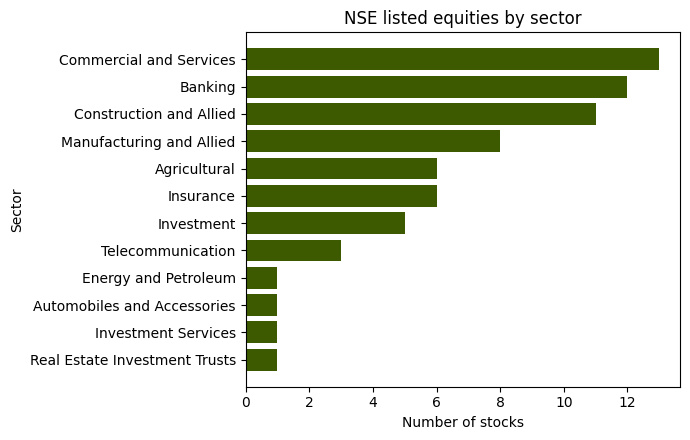

In [43]:
# An empty chart for the sector counts
figure, axis = plt.subplots()
# One bar per sector, smallest first so the largest ends up at the top
axis.barh(sector_counts["sector"][::-1], sector_counts["stock_codes"][::-1], color="#3d5a00")
# Name the chart and its axes
axis.set(title="NSE listed equities by sector", xlabel="Number of stocks", ylabel="Sector")
# Keep the sector names inside the figure
plt.tight_layout()
# Draw the sector bars
plt.show()

In [44]:
# Check your work
assert len(axis.patches) == 12, f"expected 12 bars, got {len(axis.patches)}"

Commercial and Services (13), Banking (12) and Construction and Allied (11) together hold
about half of the 68 listed names; the smallest sectors (Automobiles and Accessories, Energy
and Petroleum, Investment Services, Real Estate Investment Trusts) each have exactly 1.

### Step 1.22: Find the gap that motivates a dense grid

Pick one stock -- MSC, Mumias Sugar Company -- and compare how many sessions it was actually recorded on against how many sessions exist in the whole archive.

**Concept: why would a rolling window care about this gap?** A window function over the raw, gap-ridden rows would count '5 sessions' as 5 *present* rows, which can stretch across however many calendar weeks the gaps between them happen to cover -- the exact leakage risk Part 2's dense grid removes.

In [45]:
# MSC's own recorded rows, and the whole archive's session count
msc_rows = clean_prices_table.loc[clean_prices_table["stock_code"] == "MSC"]
# MSC's own first and last recorded date
msc_first_date = msc_rows["trade_date"].min()
# Its last recorded date
msc_last_date = msc_rows["trade_date"].max()
# How many sessions MSC actually has a row for
msc_sessions_recorded = len(msc_rows)
# How many distinct sessions the whole archive has
total_sessions_in_archive = clean_prices_table["trade_date"].nunique()
# The gap between the two
msc_sessions_missing = total_sessions_in_archive - msc_sessions_recorded

# MSC's own span, and how many of the archive's sessions it is missing
print(f"MSC: {msc_first_date.date()} to {msc_last_date.date()}, {msc_sessions_recorded} of "
      f"{total_sessions_in_archive} possible sessions recorded ({msc_sessions_missing} missing)")

MSC: 2013-01-02 to 2024-10-31, 2389 of 2941 possible sessions recorded (552 missing)


In [46]:
# Check your work
# MSC spans the full archive (it was listed before 2013 and still listed in late 2024)
assert str(msc_first_date.date()) == "2013-01-02", msc_first_date
assert str(msc_last_date.date()) == "2024-10-31", msc_last_date
# 2,389 of 2,941 possible sessions actually have a row for MSC
assert msc_sessions_recorded == 2_389, f"expected 2,389, got {msc_sessions_recorded}"
assert msc_sessions_missing == 552, f"expected 552 missing sessions, got {msc_sessions_missing}"

MSC is missing 552 of its own 2,941 bounded sessions -- over an eighth of its own trading
life has no row at all, not even a `"-"` for "not traded". A rolling window run directly on
`raw_prices` would silently stretch "the last 20 sessions" or "the next 5 sessions" across
however many calendar weeks those 552 gaps happen to fall in. Part 2 builds the dense grid
that fixes this for every one of the 68 stocks, not just MSC.

## 1C. Split

Before building the real labels on 187,792 rows, prove the leakage guard on a tiny example
where the right answer can be worked out by hand. This is the single most important
correctness check in the project: get the forward window wrong by even one row, and the
model would be trained on information it could not have known yet.

### Step 1.23: Build a 14-row sequence with one untraded session

One stock, 14 sessions, `is_untraded = 0` on every session except session 9.

**Concept: what is the trailing window supposed to answer?** `trailing_illiquid_5`: was this stock untraded on *any* of the last 5 sessions, including today? It both is the naive persistence baseline's own prediction, and defines `currently_liquid`, the population split the whole headline rests on.

In [47]:
# sql/template.py, used below to render the real SQL text
import template

# A fresh in-memory DuckDB holding only the 14-row example
example_connection = duckdb.connect(":memory:")
# A table with the one column sql/04_labels.sql actually reads
example_connection.execute('''
    CREATE TABLE features_final (stock_code VARCHAR, session_no INTEGER, is_untraded INTEGER)
''')
# Session 9 is the only untraded session; every other session trades normally
untraded_session_number = 9
# Insert all 14 sessions, one row at a time
for session_no in range(1, 15):
    # 1 on the untraded session, 0 on every other
    is_untraded_flag = 1 if session_no == untraded_session_number else 0
    example_connection.execute(
        "INSERT INTO features_final VALUES ('TEST', ?, ?)", [session_no, is_untraded_flag]
    )

# Read the 14 rows back, in session order
example_rows = example_connection.execute("SELECT * FROM features_final ORDER BY session_no").df()
# The table's type and size
print(type(example_rows).__name__, example_rows.shape)
# All 14 rows
example_rows

DataFrame (14, 3)


,stock_code,session_no,is_untraded
0,TEST,1,0
1,TEST,2,0
2,TEST,3,0
3,TEST,4,0
4,TEST,5,0
5,TEST,6,0
6,TEST,7,0
7,TEST,8,0
8,TEST,9,1
9,TEST,10,0


In [48]:
# Check your work
assert example_rows.shape == (14, 3), f"expected 14 rows, got {example_rows.shape}"
assert int(example_rows["is_untraded"].sum()) == 1, "exactly one session should be untraded"
assert example_rows.loc[example_rows["is_untraded"] == 1, "session_no"].item() == 9

### Step 1.24: Run the real sql/04_labels.sql against the example

Render `sql/04_labels.sql` through `sql/template.py` -- the exact same rendering `sql/run_sql.py` uses on the real warehouse -- and execute it against the 14-row example.

**Concept: why render it rather than paste the SQL text into the notebook?** Rendering and running the actual file means this check proves the real pipeline code is correct, not a hand-copied approximation of it that could drift out of sync.

In [49]:
# The exact text sql/run_sql.py would execute for this one file
labels_sql_text = template.render((PROJECT_DIR / "sql" / "04_labels.sql").read_text(encoding="utf-8"))
# Run it against the 14-row example, building the real "labels" table
example_connection.execute(labels_sql_text)

# Read the three label columns back, in session order
example_labels = example_connection.execute(
    "SELECT session_no, trailing_illiquid_5, currently_liquid, is_illiquid_next_5d FROM labels ORDER BY session_no"
).df()
# The result's type and size
print(type(example_labels).__name__, example_labels.shape)
# All 14 labelled rows
example_labels

DataFrame (14, 4)


,session_no,trailing_illiquid_5,currently_liquid,is_illiquid_next_5d
0,1,<NA>,<NA>,0
1,2,<NA>,<NA>,0
2,3,<NA>,<NA>,0
3,4,<NA>,<NA>,1
4,5,0,1,1
5,6,0,1,1
6,7,0,1,1
7,8,0,1,1
8,9,1,0,0
9,10,1,0,<NA>


In [50]:
# Check your work
assert example_labels.shape == (14, 4), f"expected (14, 4), got {example_labels.shape}"

### Step 1.25: Work out the trailing window by hand, then check the SQL against it

`trailing_illiquid_5` looks at today and the 4 preceding sessions; by hand, it should be NULL for the first 4 sessions (fewer than 5 rows exist yet), 0 for sessions 5-8 (the window has not yet reached session 9), 1 for sessions 9-13 (the window always includes session 9), then 0 again at session 14 (the window has moved past it).

**Concept: why NULL rather than 0 for the first 4 sessions?** A `trailing_illiquid_5` of 0 would claim 'this stock was liquid for its last 5 sessions', which is false when there have not been 5 sessions yet; NULL says 'unknown', which is the truth.

In [51]:
# The hand-worked expectation, written out before looking at the SQL's own answer
expected_trailing = {1: None, 2: None, 3: None, 4: None,
                     5: 0, 6: 0, 7: 0, 8: 0,
                     9: 1, 10: 1, 11: 1, 12: 1, 13: 1,
                     14: 0}

# The SQL's actual answer, as a plain dict keyed by session_no
actual_trailing = {}
# Walk every labelled row by hand, one session at a time
for _, row in example_labels.iterrows():
    # This row's session number
    session_number = int(row["session_no"])
    # This row's trailing value, possibly NULL
    trailing_value = row["trailing_illiquid_5"]
    if pd.isna(trailing_value):
        # A NULL stays None
        actual_trailing[session_number] = None
    else:
        # A real value becomes a plain int
        actual_trailing[session_number] = int(trailing_value)

# Whether the SQL's own answer matches the hand-worked one exactly
print("hand-worked and SQL trailing windows agree:", actual_trailing == expected_trailing)
# The SQL's answer, session by session
print(actual_trailing)

hand-worked and SQL trailing windows agree: True
{1: None, 2: None, 3: None, 4: None, 5: 0, 6: 0, 7: 0, 8: 0, 9: 1, 10: 1, 11: 1, 12: 1, 13: 1, 14: 0}


In [52]:
# Check your work
assert actual_trailing == expected_trailing, f"trailing window mismatch: {actual_trailing}"

### Step 1.26: Work out the forward window by hand, then check the SQL against it

`is_illiquid_next_5d` looks at the 5 sessions *strictly after* today (1 to 5 sessions ahead, never today itself); by hand, it should be 0 for sessions 1-3 (the window never reaches session 9), 1 for sessions 4-8 (the window always includes session 9), 0 at session 9 itself (the window has moved past it), then NULL for sessions 10-14 (fewer than 5 full sessions remain).

**Concept: why is session 9's own forward label 0, not 1?** The forward window at session 9 looks at sessions 10-14, none of which are untraded; session 9 being untraded itself is not part of its *own* forward label, which only looks ahead.

In [53]:
# The hand-worked expectation for the forward label
expected_forward = {1: 0, 2: 0, 3: 0,
                    4: 1, 5: 1, 6: 1, 7: 1, 8: 1,
                    9: 0,
                    10: None, 11: None, 12: None, 13: None, 14: None}

# The SQL's actual answer, as a plain dict keyed by session_no
actual_forward = {}
# Walk every labelled row by hand, one session at a time
for _, row in example_labels.iterrows():
    # This row's session number
    session_number = int(row["session_no"])
    # This row's forward value, possibly NULL
    forward_value = row["is_illiquid_next_5d"]
    if pd.isna(forward_value):
        # A NULL stays None
        actual_forward[session_number] = None
    else:
        # A real value becomes a plain int
        actual_forward[session_number] = int(forward_value)

# Whether the SQL's own answer matches the hand-worked one exactly
print("hand-worked and SQL forward windows agree:", actual_forward == expected_forward)
# The SQL's answer, session by session
print(actual_forward)

hand-worked and SQL forward windows agree: True
{1: 0, 2: 0, 3: 0, 4: 1, 5: 1, 6: 1, 7: 1, 8: 1, 9: 0, 10: None, 11: None, 12: None, 13: None, 14: None}


In [54]:
# Check your work
assert actual_forward == expected_forward, f"forward window mismatch: {actual_forward}"

### Step 1.27: Check currently_liquid is exactly the opposite of trailing_illiquid_5

Wherever `trailing_illiquid_5` is known, `currently_liquid` should be `1 - trailing_illiquid_5` -- this is the split between the full population and the honest, harder 'transition' population used throughout Part 3 and Part 4.

**Concept: why build a whole population split out of one flipped column?** Most of a session being 'illiquid' is a stock that was already illiquid staying that way; `currently_liquid = 1` keeps only the stocks that were NOT already illiquid today, so persistence cannot win just by repeating the present.

In [55]:
# Rows where the trailing window is known
known_trailing = example_labels.dropna(subset=["trailing_illiquid_5"])
# currently_liquid should be the exact opposite, row by row
opposite_matches = (known_trailing["currently_liquid"] == 1 - known_trailing["trailing_illiquid_5"]).all()

# Whether the opposite relationship holds on every known row
print("currently_liquid is the exact opposite of trailing_illiquid_5 on every known row:", opposite_matches)
# This toy connection is done; the real warehouse connection opens fresh in Part 2
example_connection.close()

currently_liquid is the exact opposite of trailing_illiquid_5 on every known row:

 True


In [56]:
# Check your work
assert bool(opposite_matches), "currently_liquid should be 1 - trailing_illiquid_5 wherever trailing_illiquid_5 is known"

Every one of the three windows the pipeline's labels depend on now matches a hand-worked
answer exactly, on the real SQL text. The next part builds these same labels -- and the
dense grid that makes them trustworthy on a gap-ridden real calendar -- on the full
187,792-row warehouse.

### Step 1.28: Show why the embargo removes specific rows, on this same 14-row example

Suppose, just for this toy example, that a test period started at session 10. The embargo removes `EMBARGO_DAYS` sessions before that cutoff from training; work out by hand which of the 14 example rows that excludes, and why.

**Concept: why can a training row's own forward label reach into the test period without the embargo?** A row at session 5's forward label looks at sessions 6-10 -- session 10 is in that window, so training on session 5 would let the model's target leak one session into the test period; only sessions 1-4 have a forward window that stays entirely before session 10.

In [57]:
# A toy test period starting at session 10, just to show the embargo arithmetic on 14 rows
toy_test_start_session = 10
# The last training session allowed: the embargo removes EMBARGO_DAYS sessions before the cutoff
toy_embargo_end_session = toy_test_start_session - settings.EMBARGO_DAYS - 1
# The rows this toy embargo would keep for training
toy_kept_for_training = example_labels.loc[example_labels["session_no"] <= toy_embargo_end_session]
# The rows the embargo removes: after the embargo end, but still before the test start
toy_removed_by_embargo = example_labels.loc[
    (example_labels["session_no"] > toy_embargo_end_session) & (example_labels["session_no"] < toy_test_start_session)
]

# The last session this toy embargo allows into training
print("toy embargo end session:", toy_embargo_end_session)
# The sessions kept for training
print("kept for training:", list(toy_kept_for_training["session_no"]))
# The sessions the embargo removes
print("removed by the embargo:", list(toy_removed_by_embargo["session_no"]))

toy embargo end session: 4
kept for training: [1, 2, 3, 4]
removed by the embargo: [5, 6, 7, 8, 9]


In [58]:
# Check your work
# With EMBARGO_DAYS=5 and a test start of session 10, only sessions 1-4 are kept
assert toy_embargo_end_session == 4, f"expected embargo end session 4, got {toy_embargo_end_session}"
assert list(toy_kept_for_training["session_no"]) == [1, 2, 3, 4], list(toy_kept_for_training["session_no"])
# Sessions 5-9 are removed: each one's forward window reaches session 10 or later
assert list(toy_removed_by_embargo["session_no"]) == [5, 6, 7, 8, 9], list(toy_removed_by_embargo["session_no"])

Every kept row's own forward window stays safely before session 10: session 4's forward
window is sessions 5-9. Every removed row's forward window reaches session 10 or later --
session 5's is sessions 6-10, which already touches the test period. Part 3 applies this
exact arithmetic to the real split, where the test period starts at session 2,489 and the
embargo removes sessions 2,484-2,488.

### Step 1.29: Name the real split and the walk-forward range

Print the actual split this project uses: everything before `settings.SPLIT_TEST_START_YEAR` trains, that year onward tests, with an `EMBARGO_DAYS`-session gap removed from training right before the test period starts.

**Concept: why does the embargo need to equal the forward window?** A training row's own forward label looks up to 5 sessions ahead; without a 5-session gap before the test period, the last few training rows' labels would reach into days the test period is supposed to be judging.

In [59]:
# The single headline split
print(f"train: before {settings.SPLIT_TEST_START_YEAR}, with the last {settings.EMBARGO_DAYS} "
      f"sessions before the cutoff removed | test: {settings.SPLIT_TEST_START_YEAR} onward")
# The walk-forward table repeats this with an expanding window, one year at a time
walkforward_years = list(range(settings.WALKFORWARD_FIRST_TEST_YEAR, settings.WALKFORWARD_LAST_TEST_YEAR + 1))
# The 9 years the walk-forward table tests
print(f"walk-forward test years: {walkforward_years}")

train: before 2023, with the last 5 sessions before the cutoff removed | test: 2023 onward
walk-forward test years: [2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]


In [60]:
# Check your work
assert walkforward_years[0] == 2016 and walkforward_years[-1] == 2024, walkforward_years
assert len(walkforward_years) == 9, f"expected 9 walk-forward years, got {len(walkforward_years)}"

---
# Part 2: Build the Engine

## 2A. The SQL warehouse

Five numbered SQL files turn the raw, gap-ridden `raw_prices` table into something a model
can trust: a trading calendar, a dense per-stock session grid, rolling features, the two
labels (proved correct by hand in Part 1C), and an analysis mart. Each is rendered through
`sql/template.py` (so a window size changed in `settings.py` actually changes what the SQL
computes) and run here exactly as `sql/run_sql.py` runs it, one file at a time so each one's
own job is visible.

### Step 2.1: Build the trading calendar

Run `sql/01_sessions.sql`: one row per distinct trade date, numbered in order.

**Concept: why number sessions instead of using the calendar date directly?** Every rolling window and forward label below is indexed by this `session_no`, so a weekend or public holiday is never mistaken for 'one trading session'.

In [61]:
# A fresh connection to the real warehouse, in write mode so the SQL file can create tables
connection = duckdb.connect(str(db_path))
# The real SQL file, rendered through settings.py's constants, executed on the real warehouse
connection.execute(template.render((PROJECT_DIR / "sql" / "01_sessions.sql").read_text(encoding="utf-8")))
# How many sessions it built
sessions_count = connection.execute("SELECT COUNT(*) FROM sessions").fetchone()[0]
# Done with this connection
connection.close()

# The session count just built
print("sessions table rows:", sessions_count)

sessions table rows: 2941


In [62]:
# Check your work
assert sessions_count == 2_941, f"expected 2,941 sessions, got {sessions_count}"

### Step 2.2: Build the dense per-stock session grid

Run `sql/02_session_grid.sql`: one row per (stock, session) for every session between that stock's own first and last observed trade date, whether or not a real row exists there.

**Concept: why bound each stock to its own first/last date, rather than the full 2013-2024 calendar?** Without that bound, a stock delisted partway through would read as 'illiquid' for every session after it stopped existing, which is not a liquidity signal, it is the stock no longer being there.

In [63]:
# A fresh write connection
connection = duckdb.connect(str(db_path))
# Builds stock_bounds and the dense session_grid
connection.execute(template.render((PROJECT_DIR / "sql" / "02_session_grid.sql").read_text(encoding="utf-8")))
# MSC's own bounds, and how many of its bounded sessions actually have a row
msc_bounds = connection.execute("SELECT * FROM stock_bounds WHERE stock_code = 'MSC'").df()
# The whole grid's row count
session_grid_count = connection.execute("SELECT COUNT(*) FROM session_grid").fetchone()[0]
# MSC's own rows where no close price came through the LEFT JOIN
msc_missing_in_grid = connection.execute(
    "SELECT COUNT(*) FROM session_grid WHERE stock_code = 'MSC' AND close_price IS NULL"
).fetchone()[0]
# Done with this connection
connection.close()

# The grid's own row count
print("session_grid rows:", session_grid_count)
# MSC's bounds and its missing-row count
print("MSC bounds:", msc_bounds.loc[0, "first_date"].date(), "to", msc_bounds.loc[0, "last_date"].date(),
      "| sessions with close_price NULL:", msc_missing_in_grid)

session_grid rows: 187792
MSC bounds: 2013-01-02 to 2024-10-31 | sessions with close_price NULL: 553


In [64]:
# Check your work
assert session_grid_count == 187_792, f"expected 187,792 grid rows, got {session_grid_count}"
# 552 is the count found by hand in Step 1.22 (no raw_prices row matched); this query counts
# 553, one more, because it also catches a row that DID match but whose close price could not
# be parsed -- the same single row Part 2C (Step 2.9) tracks down and explains.
assert msc_missing_in_grid == 553, f"expected 553, got {msc_missing_in_grid}"

### Step 2.3: See the 0/0 gotcha before trusting volume_zscore_60d

`sql/03_features.sql` divides by `NULLIF(STDDEV_SAMP(volume_or_zero) OVER w60, 0)` instead of the plain standard deviation; see why on a tiny toy table before running the real file.

**Concept: why is 0/0 dangerous here specifically?** A stock can go 60 straight sessions at zero volume (a real state in this market); its 60-day standard deviation is then exactly 0, and `x / 0` in SQL returns a floating-point NaN, not a NULL -- and NaN slips straight past every later `IS NOT NULL` filter.

In [65]:
# A toy table: one stock, settings.LONG_WINDOW_DAYS sessions of identical volume
toy_connection = duckdb.connect(":memory:")
# The exact window length the real 60-day feature uses
toy_rows = settings.LONG_WINDOW_DAYS
# A table of that many identical-volume rows
toy_connection.execute(f"CREATE TABLE toy_volume AS SELECT 0.0 AS volume_or_zero FROM range({toy_rows})")

# The plain division: 0 / 0 comes back as NaN, which "IS NOT NULL" does not catch
toy_naive = toy_connection.execute('''
    SELECT (volume_or_zero - AVG(volume_or_zero) OVER ()) / STDDEV_SAMP(volume_or_zero) OVER () AS naive_zscore
    FROM toy_volume LIMIT 1
''').fetchone()[0]
# The guarded division: NULLIF turns a zero standard deviation into NULL first
toy_guarded = toy_connection.execute('''
    SELECT (volume_or_zero - AVG(volume_or_zero) OVER ()) / NULLIF(STDDEV_SAMP(volume_or_zero) OVER (), 0) AS guarded_zscore
    FROM toy_volume LIMIT 1
''').fetchone()[0]
# Done with this toy connection
toy_connection.close()

# Whether the naive result is a NaN that "IS NOT NULL" would miss
naive_is_nan = pd.isna(toy_naive)
# The naive result and whether it is such a NaN
print("naive 0/0 result:", toy_naive, "| is it a NaN that IS NOT NULL would miss?", naive_is_nan)
# Whether the guarded result is a real SQL NULL
print("NULLIF-guarded result:", toy_guarded, "| is this a real NULL?", toy_guarded is None)

naive 0/0 result: nan | is it a NaN that IS NOT NULL would miss? True
NULLIF-guarded result: None | is this a real NULL? True


In [66]:
# Check your work
# The naive version is a NaN, a real Python float, not SQL's NULL
assert toy_naive is not None, "the naive division should still return something"
assert pd.isna(toy_naive), "the naive 0/0 division should be NaN"
# The guarded version is caught correctly: a real NULL
assert toy_guarded is None, "NULLIF should turn the zero-stddev division into a real NULL"

The naive division returns `nan` -- a real value as far as `IS NOT NULL` is concerned, so a
row like this would silently reach a model that cannot handle NaN. `NULLIF(..., 0)` turns the
zero standard deviation into a real SQL `NULL` first, so the division becomes `NULL` too, and
`sql/03_features.sql`'s own warmup logic (Step 2.4) then treats it the same as any other
not-yet-known feature.

### Step 2.4: Build the rolling features

Run `sql/03_features.sql` for real: `avg_volume_20d`, `volatility_20d`, `zeros_share_20d` and `volume_zscore_60d`, each computed only from today and earlier sessions.

**Concept: why is a feature NULL for a stock's first 19 (or 59) sessions?** A 20-day average computed on, say, 6 real sessions is not the 20-day figure it claims to be; `features_final` sets it to NULL until the window is full, rather than quietly returning a half-built number.

In [67]:
# A fresh write connection
connection = duckdb.connect(str(db_path))
# Builds features_final: the four rolling features, warmup-gated
connection.execute(template.render((PROJECT_DIR / "sql" / "03_features.sql").read_text(encoding="utf-8")))
# The whole table's row count
features_final_count = connection.execute("SELECT COUNT(*) FROM features_final").fetchone()[0]
# One stock's own warm-up: avg_volume_20d should be NULL until trailing_count_20d reaches 20
absa_warmup = connection.execute('''
    SELECT session_no, trailing_count_20d, avg_volume_20d
    FROM features_final WHERE stock_code = 'ABSA' ORDER BY session_no LIMIT 25
''').df()
# Done with this connection
connection.close()

# The feature table's row count
print("features_final rows:", features_final_count)
# ABSA's own rows around where the 20-day window first fills
absa_warmup.tail(6)

features_final rows: 187792


,session_no,trailing_count_20d,avg_volume_20d
19,20,20,812360.0
20,21,20,816810.0
21,22,20,852660.0
22,23,20,864645.0
23,24,20,871960.0
24,25,20,875990.0


In [68]:
# Check your work
assert features_final_count == 187_792, f"expected 187,792, got {features_final_count}"
# Every row with fewer than 20 trailing sessions has a NULL 20-day average
still_warming_up = absa_warmup.loc[absa_warmup["trailing_count_20d"] < settings.SHORT_WINDOW_DAYS]
assert still_warming_up["avg_volume_20d"].isna().all(), "a half-built 20-day average leaked through"
# The row where the window first fills has a real number
full_window = absa_warmup.loc[absa_warmup["trailing_count_20d"] >= settings.SHORT_WINDOW_DAYS]
assert full_window["avg_volume_20d"].notna().all(), "a full 20-day window should not be NULL"

### Step 2.5: Build the two labels on the real warehouse

Run `sql/04_labels.sql` for real, the same file proved correct by hand on 14 rows in Part 1C, now on all 187,792.

**Concept: what is the base rate, and why report two of them?** The base rate is the share of rows where the forward label is 1; it differs sharply between the full population (most of it already-illiquid stocks staying that way) and the transition population (stocks not already illiquid today) -- exactly the split Part 1C's `currently_liquid` column exists to make.

In [69]:
# A fresh write connection
connection = duckdb.connect(str(db_path))
# Builds the labels table: trailing_illiquid_5, currently_liquid, is_illiquid_next_5d
connection.execute(template.render((PROJECT_DIR / "sql" / "04_labels.sql").read_text(encoding="utf-8")))
# The full-population and transition-population base rates
label_distribution = connection.execute('''
    SELECT
        COUNT(*) AS rows_with_a_label,
        AVG(is_illiquid_next_5d) AS base_rate_full,
        AVG(CASE WHEN currently_liquid = 1 THEN is_illiquid_next_5d END) AS base_rate_transition,
        SUM(CASE WHEN currently_liquid = 1 THEN 1 ELSE 0 END) AS currently_liquid_rows
    FROM labels AS l
    JOIN features_final AS f ON f.stock_code = l.stock_code AND f.session_no = l.session_no
    WHERE is_illiquid_next_5d IS NOT NULL
''').df()
# Done with this connection
connection.close()

# The one summary row
label_distribution

,rows_with_a_label,base_rate_full,base_rate_transition,currently_liquid_rows
0,187452,0.408206,0.112671,110765.0


In [70]:
# Check your work
assert label_distribution.loc[0, "rows_with_a_label"] == 187_452, label_distribution.loc[0, "rows_with_a_label"]
assert abs(label_distribution.loc[0, "base_rate_full"] - 0.408206) < 1e-5, label_distribution.loc[0, "base_rate_full"]
assert abs(label_distribution.loc[0, "base_rate_transition"] - 0.112671) < 1e-5, label_distribution.loc[0, "base_rate_transition"]
assert label_distribution.loc[0, "currently_liquid_rows"] == 110_765, label_distribution.loc[0, "currently_liquid_rows"]

The forward label is 1 for 40.8% of all rows, but only 11.3% of rows that were *not already
illiquid today* -- the gap between these two numbers is the whole reason the full-population
PR-AUC in Part 3 cannot be trusted on its own.

### Step 2.6: Build the analysis mart and the watchlist

Run `sql/05_marts.sql`: `mart_features_labels` joins every feature, both labels and the stock's sector into one row per (stock, session); `mart_latest_watchlist` keeps only each stock's single most recent row.

**Concept: why is sector joined in here but never passed to a model?** The mart is read by the report and the site, which group by sector; the model in Part 3 never sees it, because a sector is static and would mostly memorise which names are already known to be thin rather than generalise.

In [71]:
# A fresh write connection
connection = duckdb.connect(str(db_path))
# Builds mart_features_labels and mart_latest_watchlist
connection.execute(template.render((PROJECT_DIR / "sql" / "05_marts.sql").read_text(encoding="utf-8")))
# The mart's own row count
mart_count = connection.execute("SELECT COUNT(*) FROM mart_features_labels").fetchone()[0]
# Each stock's single most recent row
watchlist_preview = connection.execute('''
    SELECT stock_code, stock_name, sector, trade_date, zeros_share_20d, trailing_illiquid_5
    FROM mart_latest_watchlist
''').df()
# Done with this connection
connection.close()

# The mart's and watchlist's row counts
print("mart_features_labels rows:", mart_count, "| mart_latest_watchlist rows:", watchlist_preview.shape[0])
# The 5 most untraded stocks right now
watchlist_preview.sort_values(["zeros_share_20d", "stock_code"], ascending=[False, True]).head(5)

mart_features_labels rows: 187792 | mart_latest_watchlist rows: 68


,stock_code,stock_name,sector,trade_date,zeros_share_20d,trailing_illiquid_5
11,ARM,ARM Cement Plc,Construction and Allied,2024-10-31,1.0,1
0,DCON,Deacons (East Africa) Plc,Commercial and Services,2024-10-31,1.0,1
2,HBE,Homeboyz Entertainment Plc,Commercial and Services,2024-10-31,1.0,1
3,KENO,KenolKobil Ltd,Energy and Petroleum,2019-10-11,1.0,1
4,KPLC-P4,KPLC-P4,Construction and Allied,2024-10-31,1.0,1


In [72]:
# Check your work
assert mart_count == 187_792, f"expected 187,792, got {mart_count}"
assert watchlist_preview.shape[0] == 68, f"expected 68 stocks on the watchlist, got {watchlist_preview.shape[0]}"

## 2B. Checks

Eight SQL files, each a query that must return zero rows if the warehouse is correct: no
duplicate (stock, session) rows, the grid never leaves a stock's own listed life, the
forward label is NULL only in exactly a stock's last 5 sessions, the trailing flag only in
exactly its first 4, no negative or fractional volume, dates in range, every price code
resolves to a sector.

### Step 2.7: Run the 8 correctness checks

Call `checks/run_checks.py`'s `run_checks(db_path)` directly on the real warehouse (not its `main()`, which reads a command-line path that this notebook does not have).

**Concept: why must each check return zero rows rather than, say, a 99% pass rate?** A correctness check is a guarantee, not a statistic: one duplicate row or one out-of-range date means the warehouse is wrong somewhere, not 'mostly right'.

In [73]:
# The real checks stage
import run_checks

# Every checks/*.sql file, run against the real warehouse
check_results = run_checks.run_checks(db_path)
# One PASS or FAIL line per check
for check_name, offending_rows in check_results:
    status = "PASS" if offending_rows == 0 else "FAIL"
    print(f"{status}  {check_name}: {offending_rows} offending rows")

PASS  01_no_duplicate_stock_session.sql: 0 offending rows
PASS  02_grid_within_stock_bounds.sql: 0 offending rows
PASS  03_forward_label_null_only_last_5.sql: 0 offending rows
PASS  04_trailing_flag_null_only_first_4.sql: 0 offending rows
PASS  05_features_not_null_after_warmup.sql: 0 offending rows
PASS  06_no_negative_or_fractional_volume.sql: 0 offending rows
PASS  07_dates_in_expected_range.sql: 0 offending rows
PASS  08_every_price_code_has_a_sector.sql: 0 offending rows


In [74]:
# Check your work
assert len(check_results) == 8, f"expected 8 checks, got {len(check_results)}"
total_offending_rows = 0
for check_name, offending_rows in check_results:
    total_offending_rows = total_offending_rows + offending_rows
assert total_offending_rows == 0, f"{total_offending_rows} offending rows across the 8 checks"

## 2C. The real coverage finding

Part 1B found MSC's own gap by hand. Now that the dense grid and features exist for all 68
stocks, measure how much of the whole warehouse is really untraded, and where the five
biggest gaps are.

### Step 2.8: Measure the untraded share of the whole grid

`features_final`'s own `is_untraded` flag is 1 wherever `volume IS NULL OR volume <= 0`; average it across every grid row.

**Concept: why can a session be untraded two different ways?** The source writes `"-"` for a day the stock appears in the price sheet with no volume, and separately has no row at all for a day it is not even mentioned; both mean 'nothing changed hands', so `is_untraded` treats them the same.

In [75]:
# A fresh read-only connection
connection = duckdb.connect(str(db_path), read_only=True)
# The whole grid's row count, untraded-row count and untraded share
untraded_summary = connection.execute('''
    SELECT COUNT(*) AS grid_rows, SUM(is_untraded) AS untraded_rows, AVG(CAST(is_untraded AS DOUBLE)) AS untraded_share
    FROM features_final
''').df()
# Done with this connection
connection.close()

# The one summary row
untraded_summary

,grid_rows,untraded_rows,untraded_share
0,187792,47140.0,0.251022


In [76]:
# Check your work
assert untraded_summary.loc[0, "grid_rows"] == 187_792, untraded_summary.loc[0, "grid_rows"]
assert untraded_summary.loc[0, "untraded_rows"] == 47_140, untraded_summary.loc[0, "untraded_rows"]
assert abs(untraded_summary.loc[0, "untraded_share"] - 0.251022) < 1e-5, untraded_summary.loc[0, "untraded_share"]

### Step 2.9: Find the one row that breaks a tidy three-way split

`report/make_results.py` reports coverage as three buckets -- rows with a volume figure, rows absent from the source entirely, rows present but marked not traded. Add them up and compare the total to the grid's own row count.

**Concept: why would three buckets of the same table not add up to its row count?** Only if the buckets overlap: a row can be both 'has a volume figure' and 'absent from the source entirely' if it is miscounted by one of the two tests, which is exactly what happens here once.

In [77]:
# A fresh read-only connection
connection = duckdb.connect(str(db_path), read_only=True)
# The three coverage buckets report/make_results.py computes
coverage_buckets = connection.execute('''
    SELECT
        SUM(CASE WHEN volume IS NOT NULL THEN 1 ELSE 0 END) AS rows_with_a_volume_figure,
        SUM(CASE WHEN close_price IS NULL THEN 1 ELSE 0 END) AS rows_absent_from_source_entirely,
        SUM(CASE WHEN volume IS NULL AND close_price IS NOT NULL THEN 1 ELSE 0 END) AS rows_present_but_marked_not_traded
    FROM features_final
''').df()
# The three buckets added together, as a plain scalar (there is only one row)
bucket_total = int(coverage_buckets.sum(axis=1).item())
# The grid's real row count, from Step 2.8
grid_rows = int(untraded_summary.loc[0, "grid_rows"])

# The one row that is counted in both "has a volume figure" and "absent entirely"
double_counted_row = connection.execute('''
    SELECT stock_code, trade_date, volume, close_price
    FROM features_final WHERE volume IS NOT NULL AND close_price IS NULL
''').df()
# Done with this connection
connection.close()

# The bucket total against the real row count, and the gap between them
print("bucket total:", bucket_total, "| grid rows:", grid_rows, "| difference:", bucket_total - grid_rows)
# The one row causing that gap
double_counted_row

bucket total: 187793 | grid rows: 187792 | difference: 1


,stock_code,trade_date,volume,close_price
0,MSC,2019-10-16,5400.0,NaN


In [78]:
# Check your work
# The three published buckets overlap by exactly one row, not zero
assert bucket_total - grid_rows == 1, f"expected the buckets to overlap by 1 row, got {bucket_total - grid_rows}"
assert double_counted_row.shape[0] == 1, f"expected exactly 1 double-counted row, got {double_counted_row.shape[0]}"
assert double_counted_row.loc[0, "stock_code"] == "MSC", double_counted_row.loc[0, "stock_code"]
assert str(double_counted_row.loc[0, "trade_date"].date()) == "2019-10-16", double_counted_row.loc[0, "trade_date"]

This one MSC row (16 October 2019) exists in the source with a parseable volume figure, but
its close price could not be parsed -- so it is correctly counted as "has a volume figure"
and, because `close_price IS NULL` is the test this project's own report uses for "absent
from the source entirely", it is *also* counted there, even though it is not actually
absent. `report/make_results.py`'s three coverage buckets are a useful read on where the
gaps are, but they are not a strict partition, and this is why: one row in 187,792 is
present and absent at once by that query's own tests. Not fixed here -- the mandate for this
notebook is the guided build, not an edit to `report/make_results.py`.

### Step 2.10: Find the five stocks missing the most sessions

Rank every stock by how many of its own bounded sessions have no row at all.

**Concept: why rank by count rather than by share?** A stock missing 552 of 2,941 sessions and a stock missing 50 of 200 both look similar by share, but the first one is the bigger absolute gap for anyone trying to build a 20-day or 60-day feature on it.

In [79]:
# A fresh read-only connection
connection = duckdb.connect(str(db_path), read_only=True)
# Every stock's bounded session count against its actually-recorded count, worst 5 first
most_incomplete_stocks = connection.execute('''
    WITH counted AS (
        SELECT b.stock_code, b.first_date, b.last_date,
               (SELECT COUNT(*) FROM session_grid g WHERE g.stock_code = b.stock_code) AS sessions_in_bounds,
               (SELECT COUNT(*) FROM raw_prices p WHERE p.stock_code = b.stock_code) AS sessions_actually_recorded
        FROM stock_bounds AS b
    )
    SELECT *, sessions_in_bounds - sessions_actually_recorded AS sessions_missing
    FROM counted ORDER BY sessions_missing DESC LIMIT 5
''').df()
# Done with this connection
connection.close()

# The 5 stocks missing the most sessions
most_incomplete_stocks

,stock_code,first_date,last_date,sessions_in_bounds,sessions_actually_recorded,sessions_missing
0,MSC,2013-01-02,2024-10-31,2941,2389,552
1,GLD,2015-05-09,2024-10-31,2355,1885,470
2,DCON,2015-05-09,2024-10-31,2355,2047,308
3,NBV,2015-05-09,2024-10-31,2355,2076,279
4,FAHR,2015-05-09,2022-05-31,1758,1619,139


In [80]:
# Check your work
assert most_incomplete_stocks.loc[0, "stock_code"] == "MSC", most_incomplete_stocks.loc[0, "stock_code"]
assert most_incomplete_stocks.loc[0, "sessions_missing"] == 552, most_incomplete_stocks.loc[0, "sessions_missing"]
assert most_incomplete_stocks.loc[1, "stock_code"] == "GLD", most_incomplete_stocks.loc[1, "stock_code"]
assert most_incomplete_stocks.loc[1, "sessions_missing"] == 470, most_incomplete_stocks.loc[1, "sessions_missing"]

---
# Part 3: Build Model

## 3A. Baseline

Before any model is fit, two baselines are scored on the test period, exactly as
`baseline/rule_of_thumb.py` scores them. Accuracy is never reported here: a rule that flags
nothing can still score well on it, which is exactly what persistence does on the harder
population.

### Step 3.1: Load the baseline's population

`baseline/rule_of_thumb.py`'s `load_population` reads every (stock, session) row with a complete feature set and a known forward label from `mart_features_labels`.

**Concept: what is the persistence trap?** The first thing any model (or rule) here can 'discover' is that a stock already illiquid stays illiquid; reporting only the full-population score would quietly reward that discovery instead of the real early-warning signal.

In [81]:
# The real baseline stage script
import rule_of_thumb
# The same rounding every stage script applies before writing its JSON, needed from here on
import rounding

# Every (stock, session) row with a complete feature set and a known forward label
baseline_population = rule_of_thumb.load_population()
# The table's type, size and base rate
print(type(baseline_population).__name__, baseline_population.shape,
      "| base rate:", round(float(baseline_population['is_illiquid_next_5d'].mean()), 6))
# The first three rows
baseline_population.head(3)

DataFrame (167318, 10) | base rate: 0.351941


,stock_code,session_no,trade_year,zeros_share_20d,volume_zscore_60d,avg_volume_20d,volatility_20d,trailing_illiquid_5,currently_liquid,is_illiquid_next_5d
0,ABSA,60,2013,0.0,-0.312182,1140275.0,0.023742,0,1,0
1,ABSA,61,2013,0.0,0.000065,1120945.0,0.023756,0,1,0
2,ABSA,62,2013,0.0,0.194359,1165385.0,0.026725,0,1,0


In [82]:
# Check your work
assert baseline_population.shape[0] == 167_318, f"expected 167,318 rows, got {baseline_population.shape[0]}"
assert baseline_population.shape[1] == 10, f"expected 10 columns, got {baseline_population.shape[1]}"
required_columns = {"avg_volume_20d", "zeros_share_20d", "trailing_illiquid_5", "currently_liquid"}
assert required_columns <= set(baseline_population.columns), baseline_population.columns

### Step 3.2: Score the persistence guess and the fixed rule on the test period

Find the test period's cutoff session, slice out the test rows, and score both baselines on the full population and the harder transition population (`currently_liquid == 1`), using `rule_of_thumb`'s own `test_cutoff_session` and `score_population`.

**Concept: why can persistence not even be scored meaningfully on the transition population?** `currently_liquid == 1` means the stock was NOT already illiquid, so persistence's own flag (`trailing_illiquid_5 == 1`) is false for every single one of those rows -- it flags nothing, and its PR-AUC collapses to exactly the base rate.

In [83]:
# The first session_no of the test period
baseline_cutoff = rule_of_thumb.test_cutoff_session(baseline_population)
# Every row from the cutoff onward
baseline_test_rows = baseline_population.loc[baseline_population["session_no"] >= baseline_cutoff]
# Of those, only the ones not already illiquid today
baseline_transition_rows = baseline_test_rows.loc[baseline_test_rows["currently_liquid"] == 1]

# Score both baselines on each population
baseline_full = rule_of_thumb.score_population(baseline_test_rows)
# Score the same two baselines on the harder transition population
baseline_transition = rule_of_thumb.score_population(baseline_transition_rows)

# The cutoff session this split actually used
print("cutoff session:", baseline_cutoff)
# Both baselines' scores on the full population
print("full population:", json.dumps(baseline_full, indent=2))
# Both baselines' scores on the transition population
print("transition population:", json.dumps(baseline_transition, indent=2))

cutoff session: 2489
full population: {
  "rows_scored": 25418,
  "base_rate": 0.37434101817609566,
  "persistence": {
    "pr_auc": 0.7212668056481876,
    "flagged": 9537,
    "precision": 0.8045506972842613,
    "recall": 0.806410930110352
  },
  "zeros_rule": {
    "threshold": 0.5,
    "pr_auc": 0.8977490614604056,
    "flagged": 4255,
    "precision": 0.9600470035252644,
    "recall": 0.42932212296374145
  }
}
transition population: {
  "rows_scored": 15881,
  "base_rate": 0.11598765820792141,
  "persistence": {
    "pr_auc": 0.11598765820792141,
    "flagged": 0,
    "precision": 0.0,
    "recall": 0.0
  },
  "zeros_rule": {
    "threshold": 0.5,
    "pr_auc": 0.5174133478904003,
    "flagged": 25,
    "precision": 0.84,
    "recall": 0.011400651465798045
  }
}


In [84]:
# Check your work
assert baseline_cutoff == 2_489, f"expected cutoff session 2,489, got {baseline_cutoff}"
assert baseline_full["rows_scored"] == 25_418, baseline_full["rows_scored"]
assert abs(baseline_full["persistence"]["pr_auc"] - 0.721267) < 1e-5, baseline_full["persistence"]["pr_auc"]
assert abs(baseline_full["zeros_rule"]["pr_auc"] - 0.897749) < 1e-5, baseline_full["zeros_rule"]["pr_auc"]
assert baseline_transition["rows_scored"] == 15_881, baseline_transition["rows_scored"]
# Persistence on the transition population collapses to exactly the base rate: it flags nothing
assert baseline_transition["persistence"]["flagged"] == 0, baseline_transition["persistence"]["flagged"]
assert abs(baseline_transition["persistence"]["pr_auc"] - baseline_transition["base_rate"]) < 1e-9
assert abs(baseline_transition["zeros_rule"]["pr_auc"] - 0.517413) < 1e-5, baseline_transition["zeros_rule"]["pr_auc"]
assert baseline_transition["zeros_rule"]["flagged"] == 25, baseline_transition["zeros_rule"]["flagged"]
# The exact same numbers, rounded the same way, as the committed outputs/baseline_results.json
committed_baseline_results = json.loads((PROJECT_DIR / "outputs" / "baseline_results.json").read_text())
assert rounding.round_numbers(baseline_full) == committed_baseline_results["full"], "full-population baseline should match the committed file"
assert rounding.round_numbers(baseline_transition) == committed_baseline_results["transition"], "transition-population baseline should match the committed file"

### Step 3.2b: Check what the rule's 0.517 PR-AUC actually measures

`score_population` scores the rule's PR-AUC with `average_precision_score(actual, test_rows["zeros_share_20d"])` -- the raw, continuous feature as a ranking, not the 50%-threshold flag. Confirm that directly, and see what the thresholded flag alone would have scored instead.

**Concept: why does this distinction matter?** `RULE_ZEROS_SHARE_THRESHOLD` decides which 25 rows get *flagged* (precision, recall), but it plays no part in the rule's own 0.517 PR-AUC -- that number comes from ranking every row by its raw `zeros_share_20d` value. A reader who assumes the 50% cutoff is where 0.517 comes from would be wrong about this baseline's own mechanics.

In [85]:
# The rule's PR-AUC, recomputed by hand the same way score_population does it
transition_actual = baseline_transition_rows["is_illiquid_next_5d"]
# Rank every row by its raw zeros_share_20d value, the real scoring rule_of_thumb.py uses
ranking_pr_auc = average_precision_score(transition_actual, baseline_transition_rows["zeros_share_20d"])

# What the 50%-threshold flag alone would score, if it were used as the ranking instead
thresholded_flag = (baseline_transition_rows["zeros_share_20d"] >= settings.RULE_ZEROS_SHARE_THRESHOLD).astype(int)
# Score that binary flag the same way, for comparison
flag_only_pr_auc = average_precision_score(transition_actual, thresholded_flag)

# The ranking score (what the rule is actually scored on) against the flag-only score
print("ranking by the raw feature:", round(ranking_pr_auc, 6), "| the 50%-threshold flag alone:", round(flag_only_pr_auc, 6))

ranking by the raw feature: 0.517413 | the 50%-threshold flag alone: 0.124242


In [86]:
# Check your work
# This confirms the rule's own 0.517 PR-AUC is the raw-feature ranking, not the threshold flag
assert abs(ranking_pr_auc - baseline_transition["zeros_rule"]["pr_auc"]) < 1e-9, ranking_pr_auc
# The threshold flag alone, used as a ranking, would score far worse than the real rule does
assert flag_only_pr_auc < 0.2, f"expected the flag-only score to be far below 0.517, got {flag_only_pr_auc}"

On the full population, persistence looks almost respectable (0.721 PR-AUC) purely by
repeating the present. On the transition population -- the population that actually matters
for an early warning -- persistence cannot score above its own base rate (0.116), while
ranking by `zeros_share_20d` alone reaches 0.517. This is the bar the models in 3B have to
clear. The 50% threshold still matters for Step 3.7's like-for-like flag comparison -- it is
just not where the 0.517 PR-AUC comes from.

## 3B. Iterate

`model/train_model.py` exposes `run_single_split` and `run_walkforward` with a
`build_model_fn` argument, built exactly so a different model can reuse the same split and
scoring logic. The logistic regression is the default; `model/train_challenger.py` supplies
a gradient-boosted tree model (`HistGradientBoostingClassifier`) as the challenger. Both are
fit on the same population, the same embargoed split, and scored the same way.

### Step 3.3: Load the model's population

`train_model.load_population` reads the same kind of row as the baseline's, with the same completeness filters -- both require every one of the four feature columns to be non-NULL, not just the forward label.

**Concept: why does the model's population size differ from the baseline's?** It does not: `rule_of_thumb.load_population` and `train_model.load_population` apply the exact same five `IS NOT NULL` filters, so the two populations are identical. What they both differ from is Step 2.5's 187,452 labelled rows -- the next step finds out why.

In [87]:
# The real stage-7 module: the logistic regression and the split/scoring logic it shares
import train_model

# The same five-filter population as the baseline's
model_population = train_model.load_population()
# The table's type, size and year range
print(type(model_population).__name__, model_population.shape,
      "| years:", model_population['trade_year'].min(), "to", model_population['trade_year'].max())

DataFrame (167318, 10) | years: 2013 to 2024


In [88]:
# Check your work
assert model_population.shape == (167_318, 10), f"expected (167318, 10), got {model_population.shape}"
assert model_population["trade_year"].min() == 2013 and model_population["trade_year"].max() == 2024
# This population is exactly the baseline's -- the same five filters, the same mart
assert model_population.shape[0] == baseline_population.shape[0], "the model and baseline populations should be identical"

### Step 3.3b: Find out why 20,134 of the 187,452 labelled rows are missing a feature

Query `mart_features_labels` for how many labelled rows are missing each of the four feature columns, and how much of `volume_zscore_60d`'s gap is the 60-session warmup versus the real 0/0 case from Step 2.3.

**Concept: why is a feature ever NULL once the forward label itself is known?** The forward label only needs 5 sessions of future data; a 20-day or 60-day feature needs 20 or 60 sessions of *past* data, which a stock's own early sessions, or a stretch following a long gap in the source, do not have yet.

In [89]:
# A fresh read-only connection
connection = duckdb.connect(str(db_path), read_only=True)
# How many labelled rows are missing each feature, and the real-vs-warmup split for the z-score
feature_gap_summary = connection.execute(f'''
    SELECT
        COUNT(*) AS rows_with_a_label,
        SUM(CASE WHEN m.avg_volume_20d IS NULL THEN 1 ELSE 0 END) AS avg_volume_20d_null,
        SUM(CASE WHEN m.volatility_20d IS NULL THEN 1 ELSE 0 END) AS volatility_20d_null,
        SUM(CASE WHEN m.volume_zscore_60d IS NULL THEN 1 ELSE 0 END) AS volume_zscore_60d_null,
        SUM(CASE WHEN m.volume_zscore_60d IS NULL AND f.trailing_count_60d >= {settings.LONG_WINDOW_DAYS} THEN 1 ELSE 0 END) AS zscore_real_zero_stddev_case
    FROM mart_features_labels AS m
    JOIN features_final AS f ON f.stock_code = m.stock_code AND f.session_no = m.session_no
    WHERE m.is_illiquid_next_5d IS NOT NULL
''').df()
# The same five-filter count Step 3.3 loaded, recomputed here for the comparison
rows_usable_by_model = connection.execute('''
    SELECT COUNT(*) FROM mart_features_labels
    WHERE is_illiquid_next_5d IS NOT NULL AND avg_volume_20d IS NOT NULL AND volatility_20d IS NOT NULL
      AND zeros_share_20d IS NOT NULL AND volume_zscore_60d IS NOT NULL AND trailing_illiquid_5 IS NOT NULL
''').fetchone()[0]
# Done with this connection
connection.close()

# The gap between Step 2.5's labelled rows and the model's own usable population
rows_dropped = int(feature_gap_summary.loc[0, "rows_with_a_label"]) - rows_usable_by_model
# The usable count and the dropped count
print("rows usable by the model:", rows_usable_by_model, "| rows dropped:", rows_dropped)
# The per-feature breakdown
feature_gap_summary

rows usable by the model: 167318 | rows dropped: 20134


,rows_with_a_label,avg_volume_20d_null,volatility_20d_null,volume_zscore_60d_null,zscore_real_zero_stddev_case
0,187452,1292.0,2961.0,20082.0,16070.0


In [90]:
# Check your work
assert rows_usable_by_model == 167_318, f"expected 167,318 usable rows, got {rows_usable_by_model}"
assert rows_dropped == 20_134, f"expected 20,134 dropped rows, got {rows_dropped}"
assert feature_gap_summary.loc[0, "avg_volume_20d_null"] == 1_292, feature_gap_summary.loc[0, "avg_volume_20d_null"]
# volatility_20d is NULL for more rows than avg_volume_20d's plain warmup -- Step 2.3's window
# carries the same 20-row warmup plus rows where too many daily returns inside it are NULL
assert feature_gap_summary.loc[0, "volatility_20d_null"] == 2_961, feature_gap_summary.loc[0, "volatility_20d_null"]
assert feature_gap_summary.loc[0, "volume_zscore_60d_null"] == 20_082, feature_gap_summary.loc[0, "volume_zscore_60d_null"]
# 16,070 of those 20,082 are the real 0/0 case (a full 60-session window, but a zero standard deviation)
assert feature_gap_summary.loc[0, "zscore_real_zero_stddev_case"] == 16_070, feature_gap_summary.loc[0, "zscore_real_zero_stddev_case"]

`avg_volume_20d` is NULL for exactly 1,292 rows -- the first 19 sessions of each of the 68
stocks' own lives (68 x 19 = 1,292). `volume_zscore_60d` is NULL for 20,082 rows, split into
4,012 warmup rows (68 x 59 x 1) and 16,070 rows where the window is full but the 60-session
standard deviation is genuinely zero, the real case Step 2.3's `NULLIF` guards against.
`volatility_20d` is NULL for 2,961 rows, 1,669 more than `avg_volume_20d`'s plain warmup --
the next step finds out why.

### Step 3.3c: Check why volatility_20d has 1,669 extra NULLs

For each of those 1,669 extra rows, count how many sessions in its own trailing 20-session window have no close price at all (absent from the source, Step 2.9's test), and bucket the result.

**Concept: why would a missing close price break a standard deviation, when STDDEV_SAMP ignores NULLs?** A sample standard deviation needs at least two non-NULL values to be defined at all; `STDDEV_SAMP` returns NULL with fewer than two. A missing close price breaks the daily return for that session and the one after it, so a window that is almost entirely gap can easily fall under two.

In [91]:
# A fresh read-only connection
connection = duckdb.connect(str(db_path), read_only=True)
# For every row, how many sessions in its own trailing 20-session window have no close price
nulls_in_window = connection.execute(f'''
    SELECT stock_code, session_no,
           SUM(CASE WHEN close_price IS NULL THEN 1 ELSE 0 END) OVER (
               PARTITION BY stock_code ORDER BY session_no
               ROWS BETWEEN {settings.SHORT_WINDOW_DAYS - 1} PRECEDING AND CURRENT ROW
           ) AS nulls_in_window
    FROM features_final
''').df()
# The 1,669 extra-null rows themselves
extra_null_rows = connection.execute('''
    SELECT stock_code, session_no FROM features_final
    WHERE volatility_20d IS NULL AND avg_volume_20d IS NOT NULL
''').df()
# Done with this connection
connection.close()

# Join the two in pandas, on the named key columns
extra_null_with_window = extra_null_rows.merge(nulls_in_window, on=["stock_code", "session_no"])
# How many of the 20 window sessions have no close price, for each of the 1,669 rows
window_null_counts = extra_null_with_window["nulls_in_window"].value_counts().sort_index()
# Show the bucketed counts
window_null_counts

nulls_in_window
18.0       5
19.0      10
20.0    1654
Name: count, dtype: int64

In [92]:
# Check your work
assert extra_null_with_window.shape[0] == 1_669, f"expected 1,669 extra-null rows, got {extra_null_with_window.shape[0]}"
# Every one of the 1,669 has at least 18 of its own 20 window sessions absent from the source
assert window_null_counts.index.min() == 18, window_null_counts.index.min()
assert window_null_counts.loc[18] == 5, window_null_counts.loc[18]
assert window_null_counts.loc[19] == 10, window_null_counts.loc[19]
assert window_null_counts.loc[20] == 1_654, window_null_counts.loc[20]

1,654 of the 1,669 have all 20 window sessions absent from the source, and the rest have 18
or 19 of 20 -- nearly the whole window is gap, not a scattered one or two missing sessions.
Together these overlapping gaps drop 187,452 labelled rows to the 167,318 the model and
baseline actually use -- "the population" from here on means these 167,318 usable rows, not
every row with a known forward label.

### Step 3.4: Look at both models before fitting either one

`train_model.build_model` returns an unfitted scaler+logistic-regression pipeline; `train_challenger.build_model` returns an unfitted gradient-boosted tree classifier.

**Concept: why does the challenger need no StandardScaler?** A tree splits on a raw threshold ('is avg_volume_20d above 1,200?'), so scaling every feature to the same range changes nothing about where it splits; a logistic regression's coefficients, by contrast, are only comparable to each other once every feature is on the same scale.

In [93]:
# The real stage-7b module: the gradient-boosted challenger
import train_challenger

# Two unfitted models, built exactly as the real stage scripts build them
logistic_regression_model = train_model.build_model()
# The challenger's own unfitted classifier
challenger_model = train_challenger.build_model()

# The logistic regression's own pipeline
print(logistic_regression_model)
# The challenger's own classifier
print(challenger_model)

Pipeline(steps=[('scaler', StandardScaler()),
                ('model', LogisticRegression(max_iter=1000))])
HistGradientBoostingClassifier(early_stopping=False, random_state=42)


In [94]:
# Check your work
assert isinstance(logistic_regression_model, Pipeline), "the logistic regression should be a Pipeline"
assert isinstance(logistic_regression_model.named_steps["scaler"], StandardScaler)
assert isinstance(logistic_regression_model.named_steps["model"], LogisticRegression)
assert isinstance(challenger_model, HistGradientBoostingClassifier)
assert challenger_model.early_stopping is False, "the challenger should have early_stopping disabled"

### Step 3.5: Fit the logistic regression on the single split

Call `train_model.run_single_split(model_population)`: it trains on every session before the embargo, tests on 2023-2024, and returns the standardised coefficients, the permutation importances, and both populations' scores.

**Concept: why does `run_single_split` also report permutation importance, not just the coefficients?** A logistic regression's coefficients are standardised but not comparable across features of different shapes (`avg_volume_20d` is heavy-tailed, `zeros_share_20d` is bounded to [0, 1]); permutation importance answers 'how much does shuffling this feature actually hurt PR-AUC', which is comparable regardless of the feature's own scale.

In [95]:
# The default build_model_fn and extra_diagnostics_fn are the logistic regression's own
lr_single_split = train_model.run_single_split(model_population)

# How many rows it trained on, and their base rate
print("train rows:", lr_single_split["train_rows"], "| train base rate:", round(lr_single_split["train_base_rate"], 6))
# The fitted logistic regression's own standardised coefficients
print("standardised coefficients:", lr_single_split["coefficients_standardised"])
# Its PR-AUC on both populations
print("full PR-AUC:", lr_single_split["full"]["pr_auc"], "| transition PR-AUC:", lr_single_split["transition"]["pr_auc"])

train rows: 141620 | train base rate: 0.34791
standardised coefficients: {'avg_volume_20d': -7.509967398612613, 'volatility_20d': -0.0182403545401624, 'zeros_share_20d': 2.7504171158810395, 'volume_zscore_60d': -0.006960968833121964}
full PR-AUC: 0.9144978364696713 | transition PR-AUC: 0.5837084629200038


In [96]:
# Check your work
assert lr_single_split["train_rows"] == 141_620, lr_single_split["train_rows"]
assert abs(lr_single_split["full"]["pr_auc"] - 0.914498) < 1e-5, lr_single_split["full"]["pr_auc"]
assert abs(lr_single_split["transition"]["pr_auc"] - 0.583708) < 1e-5, lr_single_split["transition"]["pr_auc"]
# avg_volume_20d's coefficient is much larger in magnitude than zeros_share_20d's
assert abs(lr_single_split["coefficients_standardised"]["avg_volume_20d"]) > abs(lr_single_split["coefficients_standardised"]["zeros_share_20d"])
# The same embargo arithmetic worked out by hand in Step 1.28, now on the real split
real_embargo_end_session = lr_single_split["cutoff_session_no"] - settings.EMBARGO_DAYS - 1
assert real_embargo_end_session == 2_483, f"expected embargo end session 2,483, got {real_embargo_end_session}"
train_rows_up_to_embargo = int((model_population["session_no"] <= real_embargo_end_session).sum())
assert train_rows_up_to_embargo == lr_single_split["train_rows"], "train_rows should match the embargo cutoff exactly"

### Step 3.6: Fit the challenger on the exact same split

Call `train_model.run_single_split(model_population, build_model_fn=train_challenger.build_model, extra_diagnostics_fn=None)`: the same population, the same cutoff, the same scoring -- only the model itself differs.

**Concept: why pass extra_diagnostics_fn=None for the challenger?** `logistic_regression_diagnostics` reads a `coef_` attribute that only a linear model has; `HistGradientBoostingClassifier` has no such attribute, so the challenger's run skips that diagnostic and relies on permutation importance alone, which both models support.

In [97]:
# Same population, same split, same scoring -- only build_model_fn changes
challenger_single_split = train_model.run_single_split(
    model_population, build_model_fn=train_challenger.build_model, extra_diagnostics_fn=None
)

# The challenger's own PR-AUC on both populations
print("full PR-AUC:", challenger_single_split["full"]["pr_auc"], "| transition PR-AUC:", challenger_single_split["transition"]["pr_auc"])
# Its own permutation importance, scale-invariant so it is comparable to the logistic regression's
print("permutation importance:", challenger_single_split["permutation_importance_pr_auc_drop"])

full PR-AUC: 0.9164551236949047 | transition PR-AUC: 0.5944870911242441
permutation importance: {'avg_volume_20d': 0.12282616211749213, 'volatility_20d': 0.0029952941309173086, 'zeros_share_20d': 0.3342539732867985, 'volume_zscore_60d': 0.0001419852011294187}


In [98]:
# Check your work
assert "coefficients_standardised" not in challenger_single_split, "the challenger should have no linear coefficients"
assert abs(challenger_single_split["full"]["pr_auc"] - 0.916455) < 1e-5, challenger_single_split["full"]["pr_auc"]
assert abs(challenger_single_split["transition"]["pr_auc"] - 0.594487) < 1e-5, challenger_single_split["transition"]["pr_auc"]

### Step 3.7: Compare both models side by side

Build one small table: both models' full and transition PR-AUC, and what each one does at the rule's own flag count (25 rows) on the transition population.

**Concept: what does 'same_flags_as_rule' actually compare?** It takes the model's 25 highest-probability transition rows -- the same number the fixed rule flags -- and scores precision and recall on exactly those 25, a like-for-like comparison rather than a cutoff chosen after seeing the test outcome.

In [99]:
# One row per model, read from each one's own single-split result
comparison_rows = []
# The logistic regression's row
comparison_rows.append({
    "model": "logistic regression",
    "full_pr_auc": lr_single_split["full"]["pr_auc"],
    "transition_pr_auc": lr_single_split["transition"]["pr_auc"],
    "same_flags_as_rule_precision": lr_single_split["transition"]["same_flags_as_rule"]["precision"],
    "same_flags_as_rule_recall": lr_single_split["transition"]["same_flags_as_rule"]["recall"],
})
# The challenger's row
comparison_rows.append({
    "model": "challenger (gradient-boosted trees)",
    "full_pr_auc": challenger_single_split["full"]["pr_auc"],
    "transition_pr_auc": challenger_single_split["transition"]["pr_auc"],
    "same_flags_as_rule_precision": challenger_single_split["transition"]["same_flags_as_rule"]["precision"],
    "same_flags_as_rule_recall": challenger_single_split["transition"]["same_flags_as_rule"]["recall"],
})
# Both rows together as one small table
single_split_comparison = pd.DataFrame(comparison_rows)
# Show the table
single_split_comparison

,model,full_pr_auc,transition_pr_auc,same_flags_as_rule_precision,same_flags_as_rule_recall
0,logistic regression,0.914498,0.583708,0.84,0.011401
1,challenger (gradient-boosted trees),0.916455,0.594487,0.92,0.012486


In [100]:
# Check your work
assert single_split_comparison.shape == (2, 5), f"expected (2, 5), got {single_split_comparison.shape}"
# The challenger has the higher transition PR-AUC on this one split
assert single_split_comparison.loc[1, "transition_pr_auc"] > single_split_comparison.loc[0, "transition_pr_auc"]
# The logistic regression ties the rule exactly at the rule's own 25 flags (84% precision)
assert abs(single_split_comparison.loc[0, "same_flags_as_rule_precision"] - 0.84) < 1e-9
# The challenger does slightly better than the rule at that same cutoff (92% precision, 23 of 25 correct)
assert abs(single_split_comparison.loc[1, "same_flags_as_rule_precision"] - 0.92) < 1e-9

On this one split, the challenger edges out the logistic regression on transition PR-AUC
(0.594 against 0.584). At the rule's own 25-flag cutoff, the logistic regression ties the
rule exactly (84% precision, 1.1% recall on both), while the challenger does slightly
better (92% precision -- 23 of 25 correct instead of 21). One split is not enough to call a
winner from this alone; Part 3C checks whether this holds up across 9 years.

### Step 3.8: Check both single-split results against the committed output files

Round both in-memory results the same way the real stage scripts do (`report/rounding.py`'s `round_numbers`), and compare them to `outputs/model_results.json` and `outputs/challenger_results.json` on disk.

**Concept: why compare to a file instead of just trusting the numbers just printed?** This is the strongest version of a Check cell: it proves the exact function this notebook just called produces the same numbers as the committed pipeline run, not just numbers that look plausible.

In [101]:
# rounding was already imported in Step 3.1; the same rounding the real stage scripts apply before writing JSON
rounded_lr_single = rounding.round_numbers(lr_single_split)
# The challenger's single-split result, rounded the same way
rounded_challenger_single = rounding.round_numbers(challenger_single_split)

# The committed logistic-regression output file
committed_model_results = json.loads((PROJECT_DIR / "outputs" / "model_results.json").read_text())
# The committed challenger output file
committed_challenger_results = json.loads((PROJECT_DIR / "outputs" / "challenger_results.json").read_text())

# Whether this notebook's own fit matches the committed file exactly
lr_matches_committed = rounded_lr_single == committed_model_results["single_split"]
# Same check for the challenger
challenger_matches_committed = rounded_challenger_single == committed_challenger_results["single_split"]
# The logistic regression's match result
print("logistic regression matches outputs/model_results.json:", lr_matches_committed)
# The challenger's match result
print("challenger matches outputs/challenger_results.json:", challenger_matches_committed)

logistic regression matches outputs/model_results.json: True
challenger matches outputs/challenger_results.json: True


In [102]:
# Check your work
assert lr_matches_committed, "the logistic regression's single-split result should match the committed file exactly"
assert challenger_matches_committed, "the challenger's single-split result should match the committed file exactly"

## 3C. Evaluate

One split is one market regime (2023-2024: thin NSE turnover, a depreciating shilling). The
walk-forward table repeats the same embargoed split nine times, one test year at a time,
refitting on an expanding window each time -- the real evidence of whether either model
holds up, and which feature actually drives the separation.

### Step 3.9: Walk the logistic regression forward across 9 years

Call `train_model.run_walkforward(model_population)`: for each year from 2016 to 2024, train on everything strictly before it (minus the embargo), test on that year's transition population alone.

**Concept: why transition-only for the walk-forward table, when the single split reports both?** The full population's score is inflated by persistence every single year for the same reason Part 3A found; reporting only the transition population keeps every year honest, not just the headline split.

In [103]:
# One row per test year, 2016-2024, transition population only
lr_walkforward_rows = train_model.run_walkforward(model_population)
# The same rows as a table
lr_walkforward = pd.DataFrame(lr_walkforward_rows)
# The columns that matter for reading the table
lr_walkforward[["test_year", "rows_scored", "base_rate", "model_pr_auc", "rule_pr_auc", "persistence_pr_auc"]]

,test_year,rows_scored,base_rate,model_pr_auc,rule_pr_auc,persistence_pr_auc
0,2016,9656,0.119511,0.537310,0.477848,0.119511
1,2017,9543,0.119040,0.481451,0.395287,0.119040
2,2018,9864,0.131184,0.552475,0.485937,0.131184
3,2019,8674,0.138806,0.551303,0.472511,0.138806
4,2020,8226,0.128009,0.554383,0.481936,0.128009
5,2021,8979,0.113598,0.624801,0.549378,0.113598
6,2022,8619,0.122056,0.521146,0.456894,0.122056
7,2023,8518,0.122564,0.545189,0.475616,0.122564
8,2024,7363,0.108380,0.632081,0.574316,0.108380


In [104]:
# Check your work
assert lr_walkforward.shape[0] == 9, f"expected 9 walk-forward years, got {lr_walkforward.shape[0]}"
assert list(lr_walkforward["test_year"]) == list(range(2016, 2025)), list(lr_walkforward["test_year"])
assert abs(lr_walkforward.loc[0, "model_pr_auc"] - 0.53731) < 1e-5, lr_walkforward.loc[0, "model_pr_auc"]
assert abs(lr_walkforward.loc[8, "model_pr_auc"] - 0.632081) < 1e-5, lr_walkforward.loc[8, "model_pr_auc"]

### Step 3.10: Walk the challenger forward across the same 9 years

Call `train_model.run_walkforward(model_population, build_model_fn=train_challenger.build_model)`: the same years, the same expanding window, only the model differs.

**Concept: why re-use run_walkforward rather than writing a second walk-forward loop in train_challenger.py?** The split, the embargo and the scoring are identical for any model; writing them twice would risk the two copies drifting apart, which is exactly what a shared, parameterised function prevents.

In [105]:
# The same 9 years, now with the challenger as the build_model_fn
challenger_walkforward_rows = train_model.run_walkforward(model_population, build_model_fn=train_challenger.build_model)
# The same rows as a table
challenger_walkforward = pd.DataFrame(challenger_walkforward_rows)
# The columns that matter for reading the table
challenger_walkforward[["test_year", "rows_scored", "base_rate", "model_pr_auc", "rule_pr_auc", "persistence_pr_auc"]]

,test_year,rows_scored,base_rate,model_pr_auc,rule_pr_auc,persistence_pr_auc
0,2016,9656,0.119511,0.517104,0.477848,0.119511
1,2017,9543,0.119040,0.469501,0.395287,0.119040
2,2018,9864,0.131184,0.562795,0.485937,0.131184
3,2019,8674,0.138806,0.528752,0.472511,0.138806
4,2020,8226,0.128009,0.552128,0.481936,0.128009
5,2021,8979,0.113598,0.632587,0.549378,0.113598
6,2022,8619,0.122056,0.520110,0.456894,0.122056
7,2023,8518,0.122564,0.551613,0.475616,0.122564
8,2024,7363,0.108380,0.646103,0.574316,0.108380


In [106]:
# Check your work
assert challenger_walkforward.shape[0] == 9, f"expected 9 walk-forward years, got {challenger_walkforward.shape[0]}"
assert abs(challenger_walkforward.loc[0, "model_pr_auc"] - 0.517104) < 1e-5, challenger_walkforward.loc[0, "model_pr_auc"]
assert abs(challenger_walkforward.loc[8, "model_pr_auc"] - 0.646103) < 1e-5, challenger_walkforward.loc[8, "model_pr_auc"]

### Step 3.10b: Check both walk-forward tables against the committed output files

The same disk comparison Step 3.8 ran on the single split, now on both 9-row walk-forward tables.

**Concept: why does this matter more for the walk-forward table than for the single split?** The walk-forward table fits 9 separate models per model family; one silent difference in any one year's fit would be easy to miss by eye in a printed table but not in an exact equality check against the committed file.

In [107]:
# The same rounding, now applied to both 9-row walk-forward tables
rounded_lr_walkforward = rounding.round_numbers(lr_walkforward_rows)
# The challenger's walk-forward rows, rounded the same way
rounded_challenger_walkforward = rounding.round_numbers(challenger_walkforward_rows)

# Whether the logistic regression's walk-forward table matches the committed file
lr_walkforward_matches_committed = rounded_lr_walkforward == committed_model_results["walkforward_by_year_transition_only"]
# Same check for the challenger
challenger_walkforward_matches_committed = rounded_challenger_walkforward == committed_challenger_results["walkforward_by_year_transition_only"]
# The logistic regression's match result
print("logistic regression walk-forward matches outputs/model_results.json:", lr_walkforward_matches_committed)
# The challenger's match result
print("challenger walk-forward matches outputs/challenger_results.json:", challenger_walkforward_matches_committed)

logistic regression walk-forward matches outputs/model_results.json: True
challenger walk-forward matches outputs/challenger_results.json: True


In [108]:
# Check your work
assert lr_walkforward_matches_committed, "the logistic regression's walk-forward table should match the committed file exactly"
assert challenger_walkforward_matches_committed, "the challenger's walk-forward table should match the committed file exactly"

### Step 3.11: Tally which model wins each year, and check both beat the rule every year

For each of the 9 years, compare the logistic regression's PR-AUC to the challenger's, and separately confirm both beat the fixed rule's PR-AUC that year.

**Concept: why does 'both beat the rule every year' matter more than 'one model beats the other'?** Beating a fixed, un-fit rule in every one of 9 years is a real, repeated result; which of two models beats the *other* by a few points in any one year is close enough that it is not the kind of claim this result can support.

In [109]:
# Walk through the 9 years by hand, naming every intermediate so nothing is hidden in a one-liner
lr_wins = 0
# How many years the challenger wins
challenger_wins = 0
# Whether the logistic regression has beaten the rule in every year seen so far
lr_beat_rule_every_year = True
# Same tracker for the challenger
challenger_beat_rule_every_year = True
# One pass per walk-forward year
for row_number in range(len(lr_walkforward)):
    # Which test year this row covers
    test_year = int(lr_walkforward.loc[row_number, "test_year"])
    # The logistic regression's PR-AUC for that year
    lr_pr_auc = lr_walkforward.loc[row_number, "model_pr_auc"]
    # The challenger's PR-AUC for the same year
    challenger_pr_auc = challenger_walkforward.loc[row_number, "model_pr_auc"]
    # The rule's PR-AUC for the same year (both models' tables agree on this, read from either)
    rule_pr_auc = lr_walkforward.loc[row_number, "rule_pr_auc"]

    if lr_pr_auc > challenger_pr_auc:
        lr_wins = lr_wins + 1
        winner = "logistic regression"
    else:
        challenger_wins = challenger_wins + 1
        winner = "challenger"
    if lr_pr_auc <= rule_pr_auc:
        lr_beat_rule_every_year = False
    if challenger_pr_auc <= rule_pr_auc:
        challenger_beat_rule_every_year = False
    print(f"{test_year}: logistic regression {lr_pr_auc:.4f} | challenger {challenger_pr_auc:.4f} | rule {rule_pr_auc:.4f} -> {winner}")

# The final tally across all 9 years
print(f"\nlogistic regression wins {lr_wins} of 9 years, challenger wins {challenger_wins} of 9 years")
# Whether the logistic regression beat the rule in every year
print("logistic regression beat the rule every year:", lr_beat_rule_every_year)
# Whether the challenger beat the rule in every year
print("challenger beat the rule every year:", challenger_beat_rule_every_year)

2016: logistic regression 0.5373 | challenger 0.5171 | rule 0.4778 -> logistic regression
2017: logistic regression 0.4815 | challenger 0.4695 | rule 0.3953 -> logistic regression
2018: logistic regression 0.5525 | challenger 0.5628 | rule 0.4859 -> challenger
2019: logistic regression 0.5513 | challenger 0.5288 | rule 0.4725 -> logistic regression
2020: logistic regression 0.5544 | challenger 0.5521 | rule 0.4819 -> logistic regression
2021: logistic regression 0.6248 | challenger 0.6326 | rule 0.5494 -> challenger
2022: logistic regression 0.5211 | challenger 0.5201 | rule 0.4569 -> logistic regression
2023: logistic regression 0.5452 | challenger 0.5516 | rule 0.4756 -> challenger
2024: logistic regression 0.6321 | challenger 0.6461 | rule 0.5743 -> challenger

logistic regression wins 5 of 9 years, challenger wins 4 of 9 years
logistic regression beat the rule every year: True
challenger beat the rule every year: True


In [110]:
# Check your work
assert lr_wins == 5, f"expected the logistic regression to win 5 years, got {lr_wins}"
assert challenger_wins == 4, f"expected the challenger to win 4 years, got {challenger_wins}"
assert lr_wins + challenger_wins == 9, "every year should go to exactly one model"
assert lr_beat_rule_every_year, "the logistic regression should beat the rule in every walk-forward year"
assert challenger_beat_rule_every_year, "the challenger should beat the rule in every walk-forward year"

Neither model wins consistently: the logistic regression takes 5 of the 9 years (2016, 2017,
2019, 2020, 2022), the challenger takes 4 (2018, 2021, 2023, 2024). That is the honest
finding -- not "the challenger wins" (it loses 5 of the 9 walk-forward years) and not "the
logistic regression wins" (it loses 4 of the 9, including both years of the single
2023-2024 split itself). What both models share, every single year without exception, is
beating the fixed rule.

### Step 3.12: Compare permutation importance between both models

Both single-split results already carry a `permutation_importance_pr_auc_drop` dict (mean PR-AUC drop on the transition test set when one raw feature is shuffled, 20 repeats, scale-invariant); put both models' numbers in one table.

**Concept: what does 'scale-invariant' solve here that the logistic regression's own coefficients could not?** `avg_volume_20d` has a standardised coefficient over twice the magnitude of `zeros_share_20d`'s, which looks like 'the more important feature' -- but `avg_volume_20d` is heavily right-skewed (most values small, a few huge) while `zeros_share_20d` is bounded to [0, 1], and a standardised coefficient on a heavy-tailed feature can be inflated by that skew alone. Permutation importance measures the actual PR-AUC cost of losing a feature, which does not care how the feature happens to be scaled.

In [111]:
# One row per feature, both models' permutation-importance PR-AUC drop side by side
lr_importance_by_feature = lr_single_split["permutation_importance_pr_auc_drop"]
# The challenger's own importances, same dict shape
challenger_importance_by_feature = challenger_single_split["permutation_importance_pr_auc_drop"]

# Built one feature at a time, so each row names both models' numbers together
permutation_rows = []
# One row per feature
for feature_name in settings.FEATURE_COLUMNS:
    permutation_rows.append({
        "feature": feature_name,
        "logistic_regression": lr_importance_by_feature[feature_name],
        "challenger": challenger_importance_by_feature[feature_name],
    })
# All four features as one small table
permutation_comparison = pd.DataFrame(permutation_rows)
# Show the table
permutation_comparison

,feature,logistic_regression,challenger
0,avg_volume_20d,0.108529,0.122826
1,volatility_20d,-0.001683,0.002995
2,zeros_share_20d,0.365777,0.334254
3,volume_zscore_60d,0.001064,0.000142


In [112]:
# Check your work
assert permutation_comparison.shape == (4, 3), f"expected (4, 3), got {permutation_comparison.shape}"
# zeros_share_20d costs both models far more PR-AUC than avg_volume_20d does when shuffled
zeros_row = permutation_comparison.loc[permutation_comparison["feature"] == "zeros_share_20d"].squeeze()
volume_row = permutation_comparison.loc[permutation_comparison["feature"] == "avg_volume_20d"].squeeze()
assert zeros_row["logistic_regression"] > 3 * volume_row["logistic_regression"], "expected zeros_share_20d to dominate for the logistic regression"
assert zeros_row["challenger"] > 2 * volume_row["challenger"], "expected zeros_share_20d to dominate for the challenger"

Shuffling `zeros_share_20d` costs the logistic regression about 0.366 of PR-AUC and the
challenger about 0.334 -- both far more than shuffling `avg_volume_20d` costs either model
(0.109 and 0.123). The other two features, `volatility_20d` and `volume_zscore_60d`, cost
next to nothing either way (one is even slightly negative for the logistic regression, a
mean over 20 repeats, which means shuffling it did not hurt the model on average -- it adds
no measurable signal of its own). This settles the question
the project's own coefficients could not: `zeros_share_20d`, not `avg_volume_20d`, is the
feature actually doing the work, for both models, even though the logistic regression's own
coefficient on `avg_volume_20d` is larger. Both models were fit on the same data and the same
split, so their agreement here is not an independent replication of the finding -- it is the
same finding checked two ways.

---
# Part 4: Communicate Results

Every figure from here on is read from `outputs/results.json`, the one file this project's
README and site are allowed to quote from.

### Step 4.1: Regenerate the results file for real

Call `report/make_results.py`'s real `main()`: it reads the warehouse, the rule log and the three model-output JSON files this notebook just confirmed against its own in-memory results (Steps 3.2, 3.8 and 3.10b), and writes one combined `outputs/results.json`.

**Concept: why call main() here instead of assembling the dict by hand?** `make_results.main()` is itself the real stage script with nothing to re-implement -- it only aggregates files already proved correct, so calling it directly is the faithful version of this step, not a shortcut.

In [113]:
# The real stage-8 script
import make_results
# Reads the warehouse, the rule log and the three model JSON files, writes results.json
make_results.main()

# The file just written, read back
results = json.loads((PROJECT_DIR / "outputs" / "results.json").read_text())
# Its type and how many top-level sections it has
print(type(results).__name__, "with", len(results), "top-level keys")
# The section names themselves
print(sorted(results.keys()))

wrote outputs\results.json
dict with 15 top-level keys
['attribution', 'baseline', 'challenger', 'checks_run', 'cleaning_rules', 'coverage', 'datasets', 'days_to_liquidate_assumptions', 'label_distribution', 'licence', 'model', 'most_incomplete_stocks', 'sectors', 'universe', 'watchlist']


In [114]:
# Check your work
assert "baseline" in results and "model" in results and "challenger" in results, sorted(results.keys())
assert results["universe"]["stock_codes"] == 68, results["universe"]

### Step 4.2: Confirm the headline figures one more time, from the regenerated file

Read the full-population and transition-population PR-AUC for persistence, the rule, the logistic regression and the challenger straight out of `results.json`.

**Concept: why re-check numbers already confirmed in Part 3?** Part 3 checked the model stages' own output files; this step checks that `make_results.py` copied them into `results.json` without changing a digit, closing the loop from raw data to the one file this project's prose is allowed to cite.

In [115]:
# One row per method, both populations' PR-AUC, read straight from results.json
headline = pd.DataFrame([
    {"method": "persistence", "full_pr_auc": results["baseline"]["full"]["persistence"]["pr_auc"],
     "transition_pr_auc": results["baseline"]["transition"]["persistence"]["pr_auc"]},
    {"method": "rule (ranking by zeros_share_20d)", "full_pr_auc": results["baseline"]["full"]["zeros_rule"]["pr_auc"],
     "transition_pr_auc": results["baseline"]["transition"]["zeros_rule"]["pr_auc"]},
    {"method": "logistic regression", "full_pr_auc": results["model"]["single_split"]["full"]["pr_auc"],
     "transition_pr_auc": results["model"]["single_split"]["transition"]["pr_auc"]},
    {"method": "challenger (gradient-boosted trees)", "full_pr_auc": results["challenger"]["single_split"]["full"]["pr_auc"],
     "transition_pr_auc": results["challenger"]["single_split"]["transition"]["pr_auc"]},
])
# All four rows together
headline

,method,full_pr_auc,transition_pr_auc
0,persistence,0.721267,0.115988
1,rule (ranking by zeros_share_20d),0.897749,0.517413
2,logistic regression,0.914498,0.583708
3,challenger (gradient-boosted trees),0.916455,0.594487


In [116]:
# Check your work
assert abs(headline.loc[0, "full_pr_auc"] - 0.721267) < 1e-5
assert abs(headline.loc[2, "transition_pr_auc"] - 0.583708) < 1e-5
assert abs(headline.loc[3, "transition_pr_auc"] - 0.594487) < 1e-5

### Step 4.3: Build the quintile chart

Call `report/make_figures.py`'s `make_quintile_chart()`: it buckets train-year rows (before 2023) into five groups by `zeros_share_20d` and plots each group's forward illiquidity rate.

**Concept: why 'train years only', and what kind of evidence is this chart?** This chart is computed on the same years the model is fit on, so it is an in-sample feature-selection check -- it shows the raw feature separates risk cleanly on its own -- not held-out validation; the walk-forward chart below is the held-out evidence.

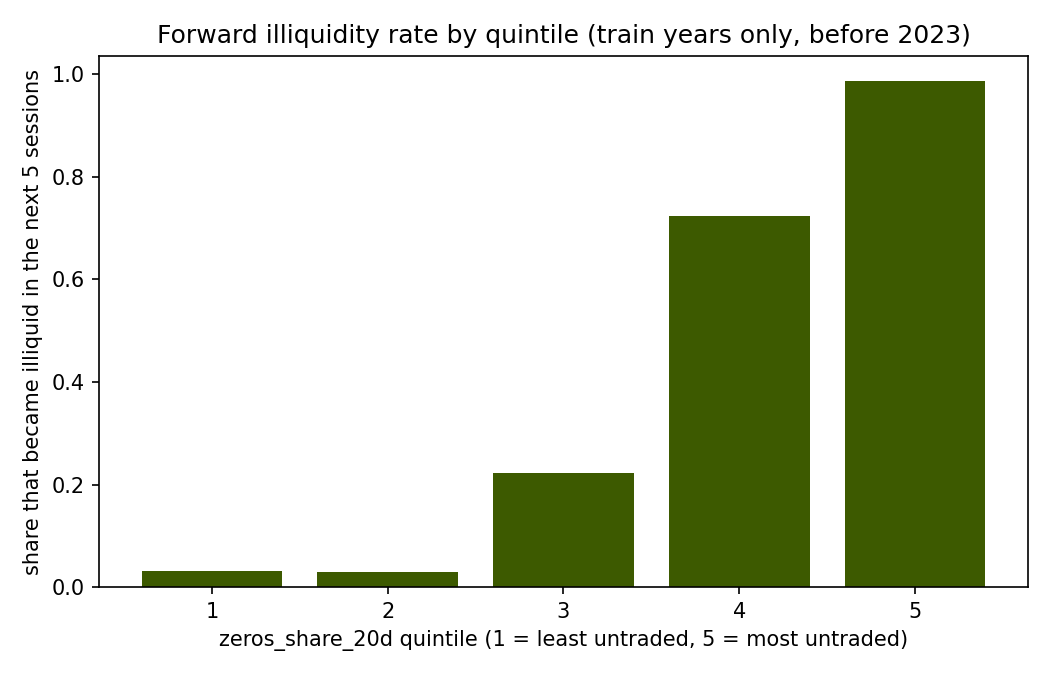

In [117]:
# The real figure-building stage; matplotlib.use("Agg") from here on, so later charts are
# shown only through saved PNGs and Image(), never a direct plt.show()
import make_figures
# Buckets train-year rows into 5 zeros_share_20d quintiles and saves the chart
make_figures.make_quintile_chart()

# Show the saved PNG inline
display(Image(filename=str(PROJECT_DIR / "figures" / "quintile_chart.png")))

In [118]:
# Check your work
assert (PROJECT_DIR / "figures" / "quintile_chart.png").exists(), "quintile_chart.png was not written"

### Step 4.3b: Read the exact rate behind each of the chart's five bars

`make_figures.py`'s own `pd_qcut_rank` groups train-year rows into five `zeros_share_20d` quintiles by rank, not by `pandas.qcut`'s usual bin edges, because most rows sit at `zeros_share_20d` exactly 0; call that same function to read the forward illiquidity rate behind each bar exactly, rather than reading it off the chart by eye.

**Concept: why not just say the chart 'rises steadily'?** The bottom two quintiles are both near 0 (most rows tie at `zeros_share_20d = 0`, so `pd_qcut_rank`'s row-order tie-break can put a few of them in quintile 1 or 2 almost arbitrarily); the honest description is where the real numbers actually show a rise, not a rounded-off version of it.

In [119]:
# A fresh read-only connection
connection = duckdb.connect(str(db_path), read_only=True)
# The same train-year rows the chart itself uses
quintile_source_rows = connection.execute(f'''
    SELECT zeros_share_20d, is_illiquid_next_5d
    FROM mart_features_labels
    WHERE trade_year < {settings.SPLIT_TEST_START_YEAR}
      AND zeros_share_20d IS NOT NULL AND is_illiquid_next_5d IS NOT NULL
''').df()
# Done with this connection
connection.close()

# The share of train-year rows tied at exactly zero -- the tie pd_qcut_rank has to split
exact_zero_share = float((quintile_source_rows["zeros_share_20d"] == 0).mean())
# make_figures.py's own ranking function, not re-implemented here
quintile_source_rows["quintile"] = make_figures.pd_qcut_rank(quintile_source_rows["zeros_share_20d"])
# The forward illiquidity rate within each of the 5 quintiles
forward_rate_by_quintile = quintile_source_rows.groupby("quintile")["is_illiquid_next_5d"].mean()
# The tie share, printed before the five rates
print(f"rows tied at zeros_share_20d exactly 0: {exact_zero_share:.1%}")
# Show the five rates
forward_rate_by_quintile

rows tied at zeros_share_20d exactly 0: 47.6%


quintile
1    0.031405
2    0.030383
3    0.222410
4    0.723742
5    0.985479
Name: is_illiquid_next_5d, dtype: float64

In [120]:
# Check your work
# Just under half of all train-year rows tie at exactly 0 -- the tie this chart's bottom two bars split
assert exact_zero_share > 0.4, f"expected over 40% of rows tied at 0, got {exact_zero_share:.1%}"
assert forward_rate_by_quintile.shape[0] == 5, f"expected 5 quintiles, got {forward_rate_by_quintile.shape[0]}"
assert abs(forward_rate_by_quintile.loc[1] - 0.031405) < 1e-5, forward_rate_by_quintile.loc[1]
assert abs(forward_rate_by_quintile.loc[3] - 0.222410) < 1e-5, forward_rate_by_quintile.loc[3]
assert abs(forward_rate_by_quintile.loc[5] - 0.985479) < 1e-5, forward_rate_by_quintile.loc[5]
# Quintiles 3 through 5 rise without reversal; only the bottom two (both near zero) do not
assert forward_rate_by_quintile.loc[3] < forward_rate_by_quintile.loc[4] < forward_rate_by_quintile.loc[5]

Quintiles 1 and 2 are both near zero (3.1% and 3.0%) -- 47.6% of train-year rows tie at
`zeros_share_20d = 0`, and the chart's row-order tie-break splits that one tied value across
the bottom two bars almost arbitrarily, so that tiny difference is not a real reversal worth
reading into.
From quintile 3 upward the rate rises sharply and without exception: 22.2%, then 72.4%, then
98.5% -- the clean separation that makes `zeros_share_20d` the feature worth building a
model around in the first place.

### Step 4.4: Build the walk-forward chart

Call `make_figures.make_walkforward_chart()`: both models' and both baselines' transition-population PR-AUC, one point per test year, 2016-2024.

**Concept: what does this chart show that Step 3.11's printed tally does not?** The printed tally says who won each year; the chart shows *by how much*, and that both models' lines sit consistently above the rule's line and far above persistence's flat one every single year.

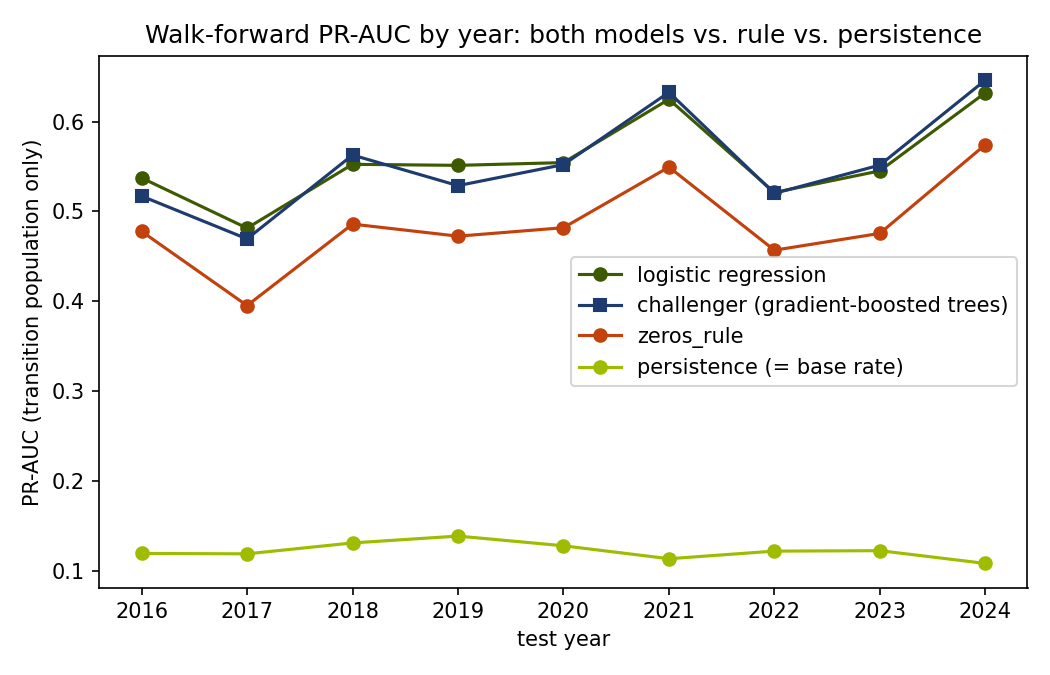

In [121]:
# Both models' and both baselines' transition PR-AUC, one point per test year
make_figures.make_walkforward_chart()

# Show the saved PNG inline
display(Image(filename=str(PROJECT_DIR / "figures" / "walkforward_chart.png")))

In [122]:
# Check your work
assert (PROJECT_DIR / "figures" / "walkforward_chart.png").exists(), "walkforward_chart.png was not written"

### Step 4.5: Build the permutation-importance chart

Call `make_figures.make_permutation_chart()`: both models' PR-AUC drop per feature, side by side.

**Concept: why show both models' bars rather than just the logistic regression's?** One model's permutation importance could be an artefact of that model's own shape; two different model families agreeing that `zeros_share_20d` dominates is a stronger answer than either one alone.

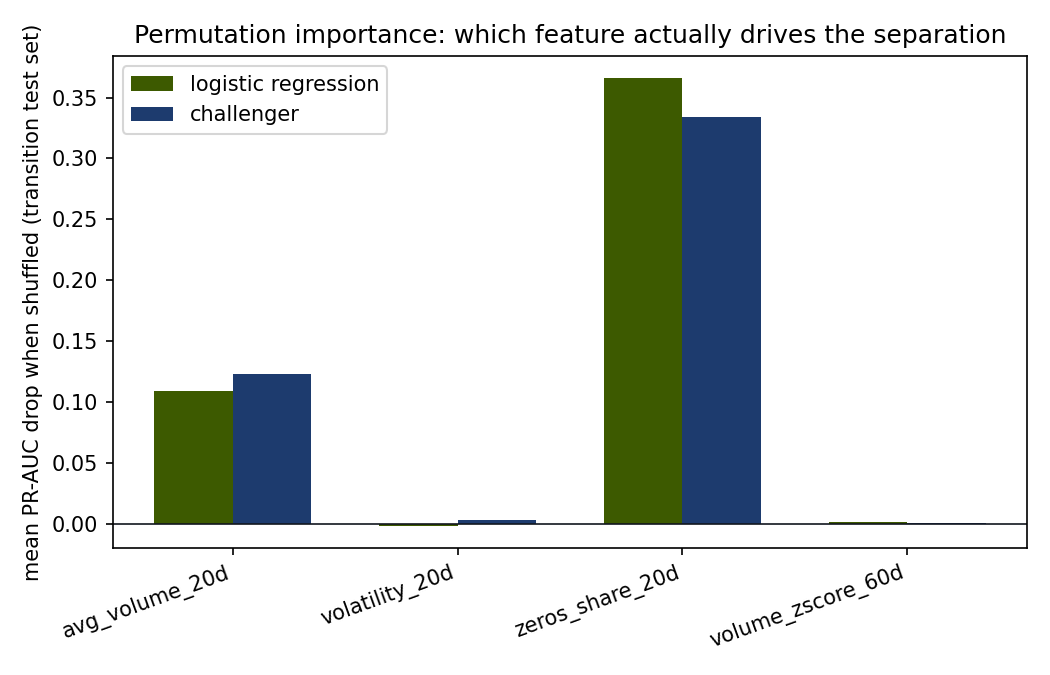

In [123]:
# Both models' PR-AUC drop per feature, side by side
make_figures.make_permutation_chart()

# Show the saved PNG inline
display(Image(filename=str(PROJECT_DIR / "figures" / "permutation_chart.png")))

In [124]:
# Check your work
assert (PROJECT_DIR / "figures" / "permutation_chart.png").exists(), "permutation_chart.png was not written"

## The headline, stated plainly

The honest headline needs the transition population, not the full one: most of a session
being "illiquid" is a stock that was already illiquid staying that way, and persistence
scores 0.721 PR-AUC on the full population purely by repeating the present. On the
transition population -- stocks that are **not** already illiquid today, the population an
early warning actually has to work on -- persistence cannot be defined usefully (it scores
exactly the 0.116 base rate), ranking by `zeros_share_20d` alone reaches 0.517, the logistic
regression reaches 0.584, and the challenger reaches 0.594.

**There is no settled winner between the two models.** The challenger has the higher PR-AUC
on the single 2023-2024 split, but across 9 walk-forward years the logistic regression wins
5 and the challenger wins 4. Reporting "the challenger is better" would overclaim a result
where the per-year winner alternates rather than settling one way. What both models share
without exception is beating that single-feature ranking, in every one of the 9 years.

**Reading the permutation chart for a non-technical reader:** of the two features that
matter, the one that actually drives the model's score is how often a stock already sat
untraded over the last 20 sessions (`zeros_share_20d`), not how much it typically traded
(`avg_volume_20d`). A desk reading this model's score for a stock should think of it mostly
as "how many of its last 20 trading days had no trade at all", not "how big is its typical
trade" -- the second number matters far less than it looks like it should from the logistic
regression's own coefficients alone.

### Step 4.6: Load the watchlist, and read it the way it is actually built

`mart_latest_watchlist` is each stock's single most recent row, sorted by `zeros_share_20d` -- a current reading, not a model score. Load it from `results.json` and look at both ends of it.

**Concept: why is the watchlist not the model's own output?** `run_single_split` and `run_walkforward` only ever return diagnostics, never a fitted model object, so nothing in this project's code path can apply either model to new rows at all -- it only ever evaluates a held-out historical split. Even if it did, the 12 names already fully untraded (this step's own table) have a NULL `volume_zscore_60d` (Step 2.3's 0/0 case): `StandardScaler` passes a NaN through unchanged, but the logistic regression step itself raises on one outright, while the challenger accepts one natively but was never trained on a missing value in this column, so a score from it there would be untested, not simply unavailable; the watchlist's other feature columns are populated for the other 56 stocks.

In [125]:
# Every stock's own most recent reading
watchlist = pd.DataFrame(results["watchlist"])

# Every stock currently fully untraded over its last 20 sessions, sorted by stock_code so the
# group shown here is the same on every run (several of these tie at zeros_share_20d = 1.0,
# and that tie order is not guaranteed stable run to run)
fully_untraded_now = watchlist.loc[watchlist["zeros_share_20d"] == 1.0].sort_values("stock_code")

# The watchlist's own size, and how many of those stocks are currently fully untraded
print("rows on the watchlist:", watchlist.shape[0], "| currently fully untraded:", fully_untraded_now.shape[0])
# The fully-untraded group itself
fully_untraded_now[["stock_code", "stock_name", "sector", "trade_date", "zeros_share_20d", "days_to_liquidate_5m"]]

rows on the watchlist: 68 | currently fully untraded: 12


,stock_code,stock_name,sector,trade_date,zeros_share_20d,days_to_liquidate_5m
11,ARM,ARM Cement Plc,Construction and Allied,2024-10-31T00:00:00.000,1.0,NaN
0,DCON,Deacons (East Africa) Plc,Commercial and Services,2024-10-31T00:00:00.000,1.0,NaN
2,HBE,Homeboyz Entertainment Plc,Commercial and Services,2024-10-31T00:00:00.000,1.0,NaN
3,KENO,KenolKobil Ltd,Energy and Petroleum,2019-10-11T00:00:00.000,1.0,NaN
4,KPLC-P4,KPLC-P4,Construction and Allied,2024-10-31T00:00:00.000,1.0,NaN
5,KPLC-P7,KPLC-P7,Construction and Allied,2024-10-31T00:00:00.000,1.0,NaN
6,KQ,Kenya Airways Plc,Commercial and Services,2024-10-31T00:00:00.000,1.0,NaN
7,KURV,Kurwitu Ventures Ltd,Investment,2024-10-31T00:00:00.000,1.0,NaN
8,LAPR,Laptrust Imara Income-REIT,Telecommunication,2024-10-31T00:00:00.000,1.0,NaN
9,LIMT,Limuru Tea Plc,Agricultural,2024-10-31T00:00:00.000,1.0,NaN


In [126]:
# Check your work
assert watchlist.shape[0] == 68, f"expected 68 stocks on the watchlist, got {watchlist.shape[0]}"
assert fully_untraded_now.shape[0] == 12, f"expected 12 stocks fully untraded, got {fully_untraded_now.shape[0]}"
# A stock with zero trailing volume has no participation rate to measure a days-to-liquidate figure from
assert fully_untraded_now["days_to_liquidate_5m"].isna().all(), "days_to_liquidate should be undefined for a fully untraded stock"
# Exactly the 12 fully-untraded rows have a NULL feature; the other 56 have all four populated
rows_with_a_null_feature = watchlist["volume_zscore_60d"].isna().sum()
assert rows_with_a_null_feature == 12, f"expected 12 rows with a NULL feature, got {rows_with_a_null_feature}"
# The watchlist's other two feature columns are never NULL for any of the 68 stocks
assert watchlist["avg_volume_20d"].notna().all(), "avg_volume_20d should never be NULL on the watchlist"
assert watchlist["zeros_share_20d"].notna().all(), "zeros_share_20d should never be NULL on the watchlist"

### Step 4.6b: Check the specific stale and mislabelled rows named below

Look up KENO, FAHR, GLD and LAPR by name, rather than trusting they will appear in whichever rows happened to print above.

**Concept: why look these four up by name instead of reading them off the table in Step 4.6?** Twelve stocks tie at `zeros_share_20d = 1.0` and only some of them are fully untraded for a stale reason; naming a row from a table whose own tie order can vary would make the prose below untraceable to a fixed printed fact.

In [127]:
# The four stocks this notebook's prose makes a specific claim about, looked up by name
caveat_codes = ["KENO", "FAHR", "GLD", "LAPR"]
# Those four rows, in a fixed order
caveat_rows = watchlist.loc[watchlist["stock_code"].isin(caveat_codes)].sort_values("stock_code")

# The columns the prose below actually cites
caveat_rows[["stock_code", "stock_name", "sector", "trade_date", "zeros_share_20d"]]

,stock_code,stock_name,sector,trade_date,zeros_share_20d
62,FAHR,Stanlib Fahari Income-REIT,Real Estate Investment Trusts,2022-05-31T00:00:00.000,0.00
12,GLD,ABSA NewGold ETF,Telecommunication,2024-10-31T00:00:00.000,0.95
3,KENO,KenolKobil Ltd,Energy and Petroleum,2019-10-11T00:00:00.000,1.00
8,LAPR,Laptrust Imara Income-REIT,Telecommunication,2024-10-31T00:00:00.000,1.00


In [128]:
# Check your work
assert caveat_rows.shape[0] == 4, f"expected all 4 caveat stocks to be on the watchlist, got {caveat_rows.shape[0]}"
keno_row = caveat_rows.loc[caveat_rows["stock_code"] == "KENO"].squeeze()
fahr_row = caveat_rows.loc[caveat_rows["stock_code"] == "FAHR"].squeeze()
gld_row = caveat_rows.loc[caveat_rows["stock_code"] == "GLD"].squeeze()
lapr_row = caveat_rows.loc[caveat_rows["stock_code"] == "LAPR"].squeeze()
assert str(keno_row["trade_date"])[:10] == "2019-10-11", keno_row["trade_date"]
assert str(fahr_row["trade_date"])[:10] == "2022-05-31", fahr_row["trade_date"]
assert gld_row["sector"] == "Telecommunication", gld_row["sector"]
assert lapr_row["sector"] == "Telecommunication", lapr_row["sector"]

Three caveats before reading the watchlist as a ranking to act on:

1. **It is a current reading, not a forward-looking score.** The 12 names above are already
   fully untraded over their last 20 sessions, and their `days_to_liquidate` is undefined
   (NULL), not just large: a stock with zero trailing volume has no participation rate to
   measure an exit time from. Persistence already tells a desk this much without needing a
   model.
2. **Some rows are stale.** `trade_date` is each stock's own *last recorded* session, not
   "today": KENO's last row, printed above, is from 2019-10-11, and FAHR's from 2022-05-31 --
   both long before the archive's own 2024-10-31 end, because those names stopped trading
   before the archive itself ends.
3. **Two sector labels on this list are wrong.** GLD ("ABSA NewGold ETF") and LAPR
   ("Laptrust Imara Income-REIT") are both recorded, as printed above, under sector
   "Telecommunication" in the source's own sector file -- neither is a telecoms company.
   Sector grouping on this list should not be trusted without checking the name.

### Step 4.7: Find the names a desk should watch before they cross the line

Filter the watchlist to stocks that are NOT already illiquid (`trailing_illiquid_5 == 0`) and look at where `zeros_share_20d` is creeping up without yet crossing the rule's 50% threshold. The watchlist itself is only ever this single-feature ranking (Step 4.6) -- neither model has ever been run against it.

**Concept: why is this subset more useful to a desk than the top of the whole list?** The 12 names already at `zeros_share_20d = 1.0` need no model -- persistence already flags them. This subset is where a desk still has time to act before a position gets stuck, and it is exactly the kind of row the held-out test in Part 3 is about: on the 2023-2024 transition test, both models scored higher than ranking by `zeros_share_20d` alone (0.584 and 0.594 against 0.517, Step 4.2).

In [129]:
# Stocks on the watchlist that are not already illiquid today
not_yet_illiquid = watchlist.loc[watchlist["trailing_illiquid_5"] == 0]
# Of those, the ones with the highest zeros_share_20d -- the ones drifting toward illiquid
watching_closely = not_yet_illiquid.sort_values(["zeros_share_20d", "stock_code"], ascending=[False, True]).head(8)

# How many of the 68 stocks are not already illiquid
print("stocks not already illiquid:", not_yet_illiquid.shape[0], "of", watchlist.shape[0])
# The 8 drifting closest to illiquid
watching_closely[["stock_code", "stock_name", "zeros_share_20d", "avg_kes_value_traded_20d", "days_to_liquidate_5m"]]

stocks not already illiquid: 43 of 68


,stock_code,stock_name,zeros_share_20d,avg_kes_value_traded_20d,days_to_liquidate_5m
17,BKG,BK Group Plc,0.35,13736.5,1819.968697
19,OCH,Olympia Capital Holdings Ltd,0.30,5325.0,4694.835681
27,LBTY,Liberty Kenya Holdings Ltd,0.15,46875.0,533.333333
30,EVRD,Eveready East Africa Ltd,0.05,15562.8,1606.394736
29,JUB,Jubilee Holdings Ltd,0.05,1656650.0,15.090695
28,NBV,Nairobi Business Ventures Ltd,0.05,34077.5,733.621891
33,PORT,East African Portland Cement Ltd,0.05,166518.0,150.133919
32,SGL,Standard Group Plc,0.05,6187.5,4040.404040


In [130]:
# Check your work
assert not_yet_illiquid.shape[0] < watchlist.shape[0], "some stocks should already be illiquid"
assert (watching_closely["zeros_share_20d"] < settings.RULE_ZEROS_SHARE_THRESHOLD).all() or watching_closely.shape[0] == 0, "this subset should sit below the rule's own threshold"
# The three names the prose below cites by name are really in this table
named_stocks = {"BKG", "OCH", "LBTY"}
assert named_stocks <= set(watching_closely["stock_code"]), "BKG, OCH and LBTY should all be in this table"
# They are not just somewhere in the top 8 -- they are strictly the three highest
top_three = watching_closely.head(3)
assert list(top_three["stock_code"]) == ["BKG", "OCH", "LBTY"], list(top_three["stock_code"])
others = watching_closely.loc[~watching_closely["stock_code"].isin(named_stocks)]
assert top_three["zeros_share_20d"].min() > others["zeros_share_20d"].max(), "BKG, OCH and LBTY should strictly outrank the rest of this table"

This is the group an investment desk should actually watch: BKG, OCH and LBTY are not
flagged by the fixed rule today (their `zeros_share_20d` sits below 50%), but they are the
three highest `zeros_share_20d` values among the names not yet illiquid -- exactly the kind
of row the held-out test in Part 3 is about. On the 2023-2024 transition test, both models
scored higher than ranking by `zeros_share_20d` alone (0.584 and 0.594 against 0.517, Step
4.2); the 50% cutoff is a separate tool, which flagged only 25 of 15,881 rows in that same
test (Step 3.2). The illustrative
`days_to_liquidate` column (a 20%-participation execution rule, not a market-impact model)
is meaningful for names in *this* table, which still trade something: exiting takes
materially longer the lower a stock's average traded value sits. For a position already
stuck in a name from Step 4.6's fully-untraded list, that same column is undefined, which is
itself the honest answer -- there is no current trading volume to estimate an exit time
from at all.

### Step 4.7b: Verify the two limitations about returns and volume_zscore_60d, by query

Two claims in the limitations below need checking against the warehouse, not just restated from memory: how often an untraded day's return is exactly zero, and how often `volume_zscore_60d` is genuinely undefined despite a full 60-session window.

**Concept: why check a limitation with a query rather than just writing it down?** `notebooks-and-output.md`'s own rule for this project: every figure in prose is printed by a cell or checked against a results file, so a limitation cannot drift from what the data actually shows any more than a headline number can.

In [131]:
# A fresh read-only connection
connection = duckdb.connect(str(db_path), read_only=True)
# Among untraded sessions with a known return, how many have a return of exactly 0?
echoed_close_check = connection.execute('''
    SELECT COUNT(*) AS untraded_with_a_return, SUM(CASE WHEN daily_return = 0 THEN 1 ELSE 0 END) AS zero_return
    FROM features_final WHERE is_untraded = 1 AND daily_return IS NOT NULL
''').df()
# Rows with a full 60-session window, but still a NULL z-score: the real 0/0 case from Step 2.3
real_zero_stddev_rows = connection.execute(f'''
    SELECT COUNT(*) FROM features_final WHERE trailing_count_60d >= {settings.LONG_WINDOW_DAYS} AND volume_zscore_60d IS NULL
''').fetchone()[0]
# Done with this connection
connection.close()

# The share of untraded-with-a-return sessions whose return is exactly 0
echoed_close_share = float(echoed_close_check.loc[0, "zero_return"] / echoed_close_check.loc[0, "untraded_with_a_return"])
# That share, printed as a percentage
print(f"untraded sessions with a 0% return: {echoed_close_check.loc[0, 'zero_return']:.0f} of "
      f"{echoed_close_check.loc[0, 'untraded_with_a_return']:.0f} ({echoed_close_share:.1%})")
# The count of genuinely undefined 60-day z-scores
print("rows with a full 60-session window but a genuinely undefined z-score:", real_zero_stddev_rows)

untraded sessions with a 0% return: 45138 of 45373 (99.5%)
rows with a full 60-session window but a genuinely undefined z-score: 16128


In [132]:
# Check your work
assert abs(echoed_close_share - 0.994821) < 1e-5, echoed_close_share
# 16,128 here, not Step 3.3b's 16,070: this query is not restricted to rows with a known
# forward label, so it also counts rows in a stock's last 5 (unlabelled) sessions
assert real_zero_stddev_rows == 16_128, f"expected 16,128, got {real_zero_stddev_rows}"

This 16,128 is not a contradiction of Step 3.3b's 16,070 -- the two queries count the same
0/0 case over two different row sets. 16,070 is restricted to rows with a known forward
label (the model's own population); 16,128 is every row in `features_final`, including the
58 extra ones in a stock's last 5 sessions, where the forward label is not yet known but the
60-day window can still be full.

## What you built

A DuckDB warehouse built from four real, messy public CSV releases spanning 2013-2024, with
two documented schema eras and a sign bug found and fixed in the data itself; a dense
per-stock session grid that turns a gap-ridden trading calendar into something a rolling
window can trust; two labels proved correct on a 14-row hand-worked example before they ran
on 187,792 real rows; 8 SQL correctness checks; two honest baselines; a logistic regression
and a gradient-boosted challenger, fit on the same embargoed split and compared the same
way; a 9-year walk-forward table; and a permutation-importance chart that resolved which of
two candidate features actually drives the result.

## Limitations

- **Neither model has ever been run against the watchlist.** `run_single_split` and
  `run_walkforward` return diagnostics, never a fitted model object (Step 4.6), so the
  watchlist is a current reading ranked by `zeros_share_20d` alone, not a model score. The
  12 fully-untraded names (Step 4.6) also have a NULL `volume_zscore_60d`, which
  `train_model.load_population`'s own filter excludes from the model's population entirely.
- **Returns are computed from the raw close**, which the source echoes unchanged on an
  untraded day rather than leaving blank: 99.48% of untraded sessions with a known return
  show exactly 0% (Step 4.7b). A day with no trade is not really a zero-return day, it is a
  missing one, which understates true 20-day return volatility on the thinnest names.
- **`volume_zscore_60d` is genuinely undefined**, not computed or imputed, for 16,128 rows
  with a full 60-session window but a real zero standard deviation (Step 4.7b, the same case
  Step 2.3 showed with a toy example) -- confirmed a real, recurring state in this market,
  not a bug.
- **Sector is shown for grouping only**, never a model feature (it is static, and a sector
  or stock dummy would mostly memorise which names are already known to be thin rather than
  generalise). Two of its labels are themselves wrong (Step 4.6b): GLD and LAPR are both
  recorded under "Telecommunication".
- **The standardised coefficients describe association within this sample**, not a causal
  claim; Step 3.12's permutation importance is the more trustworthy "what matters" answer,
  not an additional, independent confirmation of it.
- **The coverage buckets in `report/make_results.py` are not a strict partition** (Step
  2.9): one MSC row is counted in two buckets at once because it matched the source but had
  an unparseable close price, not because it is truly absent.
- **The "days to exit" column is an illustrative 20%-participation rule**, not a
  market-impact model.
- **Neither model beats the other consistently** (Step 3.11): this is reported as the
  honest result, not resolved into a single winner.
- **Kenya Power's two preference-share lines (KPLC-P4, KPLC-P7) are kept as separate listed
  instruments**, not merged with the ordinary KPLC line.
- **This is a frozen historical archive, ending 2024-10-31** (Step 1.20), not a live feed --
  every finding here describes 2013-2024 Nairobi Securities Exchange trading, not a
  prediction about today's market.

## Next steps

- Re-run the walk-forward table on a longer run of years once more archive data exists, to
  see whether the 5-4 split between the two models resolves one way as more years accumulate,
  or stays genuinely unsettled.
- Try a model using only `zeros_share_20d` and `avg_volume_20d` (Step 3.12 found the other
  two features cost next to nothing) to see whether a two-feature model performs
  indistinguishably from the four-feature one -- left open by this notebook, not tested.
- Fix the one double-counted MSC row and the two mislabelled sectors found in Steps 2.9 and
  4.6b, in `report/make_results.py` and the sector source data respectively (not done here,
  since this notebook's own mandate is the guided build, not an edit to those files).
- Replace the illustrative `days_to_liquidate` participation rule with a real market-impact
  model, if this were ever used to size an actual position rather than to rank a watchlist.
- Change `run_single_split` to return the fitted model object alongside its diagnostics, so
  it can be scored against each stock's latest row -- today it returns only diagnostics
  (Step 4.6). The 12 fully-untraded names would still need a decision for their NULL
  `volume_zscore_60d`: `StandardScaler` passes a NaN through unchanged, but the logistic
  regression step itself raises on one outright, so it would need an imputed value or a
  separate rule, while the challenger would accept the NaN natively but has never been
  trained on a missing value there, so its score on those names would need validating, not
  simply trusting.